
# P2 — Supervised Regression

This notebook evaluates classical machine-learning and deep-learning methods for predicting photovoltaic (PV) output power from irradiance, weather, and temporal features.

## 1. Experimental Scenarios

### A. Same-City Regression
Train and evaluate models independently on:
- **Davis (2014–2016)**
- **Amherst (2018–2020)**

Each dataset uses a chronological 80/20 train–test split.

### B. Cross-City Regression (Zero-Shot)
Train models on **Davis (2011–2016)** and evaluate them directly on **Huron, Santa Barbara, and La Jolla**, without using target-city data for training or preprocessing.

### C. Sequential Forecasting
Use the previous **12 observations** to predict the next observation's Output Power. Classical and deep-learning forecasting methods are compared.

### D. Three-Year vs. Six-Year Training
Compare regression performance using three-year and six-year datasets, with independent chronological 80/20 splits.

## 2. Experimental Setup

- **Target variable:** Output Power (kW).
- **Methods:** Ridge Regression, SVR, Random Forest, XGBoost, and neural-network models.
- **Reproducibility:** Three fixed random seeds (42, 123, 2026).
- **Preprocessing:** Feature transformations are fitted only on permitted training data.
- **Evaluation:** All results are calculated on held-out test observations.

## 3. Evaluation Metrics

**Root Mean Squared Error (RMSE):**

$$
\mathrm{RMSE} =
\sqrt{\frac{1}{N}\sum_{i=1}^{N}(y_i-\hat{y}_i)^2}
$$

**Mean Absolute Error (MAE):**

$$
\mathrm{MAE} =
\frac{1}{N}\sum_{i=1}^{N}|y_i-\hat{y}_i|
$$

**Normalized RMSE (nRMSE):**

$$
\mathrm{nRMSE} =
\frac{\mathrm{RMSE}}{y_{\max}-y_{\min}}\times 100\%
$$

The normalization range is computed from the valid ground-truth observations in each evaluation set. Lower values indicate better regression performance.

## 4. Results and Visualization

- Compare all models using RMSE, MAE, and nRMSE (mean ± standard deviation across three seeds).
- Visualize model comparisons and prediction-versus-ground-truth performance.
- Identify and discuss the highest-performing models in each experimental scenario.
- Save experiment results independently of final visualizations.
- Export compact, publication-quality PDF figures for Overleaf.


In [1]:

# ============================================================
# P2 — Cell 2: Portable Setup and Dataset Loading
# ============================================================

import os
import platform
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# 1. Locate the project directory
# ------------------------------------------------------------

PROJECT_NAME = "Code_base_v2"

# Optional override for a custom local project location.
# Example: Path(r"C:\Users\Student\ML_Project\Code_base_v2")
PROJECT_ROOT_OVERRIDE = None

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")


def locate_project():
    """Find the project root on Colab or a local computer."""

    configured = (
        PROJECT_ROOT_OVERRIDE
        or os.environ.get("ECE579_PROJECT_ROOT")
    )

    if configured:
        root = Path(configured).expanduser().resolve()

        if not (root / "Data" / "Processed").is_dir():
            raise FileNotFoundError(
                f"Processed data directory not found: {root}"
            )

        return root

    current = Path.cwd().resolve()

    for folder in [current, *current.parents]:

        if (folder / "Data" / "Processed").is_dir():
            return folder

        candidate = folder / PROJECT_NAME

        if (candidate / "Data" / "Processed").is_dir():
            return candidate.resolve()

    if IN_COLAB:
        candidate = (
            Path("/content/drive/MyDrive")
            / "Colab Notebooks"
            / "ML_ECE_571_Project"
            / PROJECT_NAME
        )

        if (candidate / "Data" / "Processed").is_dir():
            return candidate.resolve()

    raise FileNotFoundError(
        "Cannot locate Code_base_v2. "
        "Set PROJECT_ROOT_OVERRIDE to its directory, "
        "or run 00_Data_Preparation.ipynb first."
    )


PROJECT_ROOT = locate_project()

PROCESSED_DIR = PROJECT_ROOT / "Data" / "Processed"
SPLITS_DIR = PROCESSED_DIR / "Splits"

RESULTS_DIR = PROJECT_ROOT / "Results" / "P2"
FIGURES_DIR = PROJECT_ROOT / "Figures" / "P2"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SEEDS = (42, 123, 2026)
TARGET_COLUMN = "Output Power"


# ------------------------------------------------------------
# 2. Register all available datasets
# ------------------------------------------------------------

DATASETS = {
    "Amherst_3yr": "Amherst_2018_2020",
    "Davis_3yr": "Davis_2014_2016",
    "Huron_3yr": "Huron_2014_2016",
    "SantaBarbara_3yr": "SantaBarbara_2014_2016",
    "LaJolla_3yr": "LaJolla_2014_2016",
    "Davis_6yr": "Davis_2011_2016",
    "Huron_6yr": "Huron_2011_2016",
    "SantaBarbara_6yr": "SantaBarbara_2011_2016",
    "LaJolla_6yr": "LaJolla_2011_2016"
}


# ------------------------------------------------------------
# 3. Load datasets and verify their chronological splits
# ------------------------------------------------------------

P2_DATA = {}
summary_records = []

for dataset_key, filename in DATASETS.items():

    data_path = PROCESSED_DIR / f"{filename}.csv"

    split_path = (
        SPLITS_DIR
        / f"{filename}_chronological_80_20.csv"
    )

    if not data_path.is_file() or not split_path.is_file():
        raise FileNotFoundError(
            f"Missing processed dataset or split: {filename}\n"
            "Run 00_Data_Preparation.ipynb first."
        )

    df = pd.read_csv(
        data_path,
        parse_dates=["Timestamp"]
    )

    splits = pd.read_csv(
        split_path,
        parse_dates=["Timestamp"]
    )

    # Verify saved data and split alignment.
    assert len(df) == len(splits)

    np.testing.assert_array_equal(
        df["row_index"].to_numpy(),
        splits["row_index"].to_numpy()
    )

    np.testing.assert_array_equal(
        df["Timestamp"].to_numpy(),
        splits["Timestamp"].to_numpy()
    )

    assert df["Timestamp"].is_monotonic_increasing
    assert not df["Timestamp"].duplicated().any()

    train_mask = splits["split"].eq("train").to_numpy()
    test_mask = splits["split"].eq("test").to_numpy()

    assert (train_mask | test_mask).all()
    assert not (train_mask & test_mask).any()

    expected_train = int(0.80 * len(df))

    assert train_mask.sum() == expected_train
    assert test_mask.sum() == len(df) - expected_train

    assert (
        df.loc[train_mask, "Timestamp"].max()
        < df.loc[test_mask, "Timestamp"].min()
    )

    power = df[TARGET_COLUMN].to_numpy(dtype=float)
    valid_power = np.isfinite(power)

    # Verify target validity against the saved manifest.
    np.testing.assert_array_equal(
        splits["valid_output_power"].to_numpy(dtype=bool),
        valid_power
    )

    # Every supervised training target must be available.
    assert valid_power[train_mask].all()

    P2_DATA[dataset_key] = {
        "data": df,
        "train_mask": train_mask,
        "test_mask": test_mask,
        "valid_power": valid_power
    }

    summary_records.append({
        "Dataset": dataset_key,
        "Total Rows": len(df),
        "Train": int(train_mask.sum()),
        "Test": int(test_mask.sum()),
        "Valid Test Power": int(
            (test_mask & valid_power).sum()
        ),
        "Missing Test Power": int(
            (test_mask & ~valid_power).sum()
        ),
        "Start": df["Timestamp"].min().date(),
        "End": df["Timestamp"].max().date()
    })

    print(f"[PASS] {dataset_key}", flush=True)


# ------------------------------------------------------------
# 4. Display the project and dataset summary
# ------------------------------------------------------------

print("\nP2 — REGRESSION DATASET SETUP")
print("=" * 80)

print(f"Platform       : {platform.system()}")
print(f"Python         : {platform.python_version()}")
print(f"Environment    : {'Google Colab' if IN_COLAB else 'Local'}")
print(f"Project root   : {PROJECT_ROOT}")
print(f"Random seeds   : {SEEDS}")

print("\nAVAILABLE DATASETS")

dataset_summary = pd.DataFrame(summary_records)
display(dataset_summary)

print("\nEXPERIMENTAL DATA AVAILABILITY")

print("Same-city     : Davis_3yr, Amherst_3yr")
print("Cross-city    : Davis_6yr -> Huron, Santa Barbara, La Jolla")
print("Sequential    : Chronological observations available")
print("3yr vs 6yr   : Davis, Huron, Santa Barbara, La Jolla")

print("\nRESULT STORAGE")

print(f"Metrics / predictions : {RESULTS_DIR}")
print(f"Final report figures  : {FIGURES_DIR}")

print("\nAll nine datasets loaded and verified successfully.")
print("No model preprocessing has been fitted.")
print("No models have been trained.")


Mounted at /content/drive
[PASS] Amherst_3yr
[PASS] Davis_3yr
[PASS] Huron_3yr
[PASS] SantaBarbara_3yr
[PASS] LaJolla_3yr
[PASS] Davis_6yr
[PASS] Huron_6yr
[PASS] SantaBarbara_6yr
[PASS] LaJolla_6yr

P2 — REGRESSION DATASET SETUP
Platform       : Linux
Python         : 3.13.16
Environment    : Google Colab
Project root   : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2
Random seeds   : (42, 123, 2026)

AVAILABLE DATASETS


,Dataset,Total Rows,Train,Test,Valid Test Power,Missing Test Power,Start,End
0,Amherst_3yr,12056,9644,2412,2408,4,2018-01-01,2020-12-31
1,Davis_3yr,12056,9644,2412,2412,0,2014-01-01,2016-12-31
2,Huron_3yr,12056,9644,2412,2412,0,2014-01-01,2016-12-31
3,SantaBarbara_3yr,12056,9644,2412,2412,0,2014-01-01,2016-12-31
4,LaJolla_3yr,12056,9644,2412,2412,0,2014-01-01,2016-12-31
5,Davis_6yr,24112,19289,4823,4823,0,2011-01-01,2016-12-31
6,Huron_6yr,24112,19289,4823,4823,0,2011-01-01,2016-12-31
7,SantaBarbara_6yr,24112,19289,4823,4823,0,2011-01-01,2016-12-31
8,LaJolla_6yr,24112,19289,4823,4823,0,2011-01-01,2016-12-31



EXPERIMENTAL DATA AVAILABILITY
Same-city     : Davis_3yr, Amherst_3yr
Cross-city    : Davis_6yr -> Huron, Santa Barbara, La Jolla
Sequential    : Chronological observations available
3yr vs 6yr   : Davis, Huron, Santa Barbara, La Jolla

RESULT STORAGE
Metrics / predictions : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P2
Final report figures  : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Figures/P2

All nine datasets loaded and verified successfully.
No model preprocessing has been fitted.
No models have been trained.


In [2]:

# ============================================================
# P2 — Cell 3: Features and Chronological Data Partitions
# ============================================================

# ------------------------------------------------------------
# 1. Define the regression input features
# ------------------------------------------------------------

EXCLUDED_COLUMNS = {
    "row_index",
    "Timestamp",
    TARGET_COLUMN
}

TIME_FEATURES = [
    "Hour_Sin",
    "Hour_Cos",
    "DayOfYear_Sin",
    "DayOfYear_Cos"
]

CATEGORICAL_FEATURES = ["Cloud Type"]

REFERENCE_DATASET = "Davis_3yr"

REFERENCE_COLUMNS = [
    column
    for column in P2_DATA[REFERENCE_DATASET]["data"].columns
    if column not in EXCLUDED_COLUMNS
]

assert "Cloud Type" in REFERENCE_COLUMNS

NUMERIC_FEATURES = [
    column
    for column in REFERENCE_COLUMNS
    if column not in CATEGORICAL_FEATURES
] + TIME_FEATURES

ALL_FEATURES = (
    [c for c in REFERENCE_COLUMNS if c not in CATEGORICAL_FEATURES]
    + TIME_FEATURES
    + CATEGORICAL_FEATURES
)

assert TARGET_COLUMN not in ALL_FEATURES
assert len(ALL_FEATURES) == len(set(ALL_FEATURES))


# ------------------------------------------------------------
# 2. Prepare features and chronological partitions
# ------------------------------------------------------------

P2_FEATURES = {}

partition_records = []

for dataset_name, dataset in P2_DATA.items():

    df = dataset["data"]

    # Every city must have the same input-feature schema.
    available_columns = [
        column
        for column in df.columns
        if column not in EXCLUDED_COLUMNS
    ]

    assert set(available_columns) == set(REFERENCE_COLUMNS), (
        f"Inconsistent features in {dataset_name}"
    )

    X = df[REFERENCE_COLUMNS].copy()

    # Cyclical time representation.
    # These transformations require no fitted parameters.
    timestamps = df["Timestamp"]

    hour = (
        timestamps.dt.hour
        + timestamps.dt.minute / 60.0
        + timestamps.dt.second / 3600.0
    )

    day_of_year = timestamps.dt.dayofyear

    X["Hour_Sin"] = np.sin(
        2 * np.pi * hour / 24.0
    )

    X["Hour_Cos"] = np.cos(
        2 * np.pi * hour / 24.0
    )

    X["DayOfYear_Sin"] = np.sin(
        2 * np.pi * day_of_year / 365.25
    )

    X["DayOfYear_Cos"] = np.cos(
        2 * np.pi * day_of_year / 365.25
    )

    # Treat cloud type as a categorical predictor.
    X["Cloud Type"] = (
        X["Cloud Type"]
        .astype("string")
        .fillna("Unknown")
        .astype(str)
    )

    # Verify numeric predictors.
    for column in NUMERIC_FEATURES:

        X[column] = pd.to_numeric(
            X[column],
            errors="raise"
        )

    if not np.isfinite(
        X[NUMERIC_FEATURES].to_numpy(dtype=float)
    ).all():
        raise ValueError(
            f"Missing or non-finite features: {dataset_name}"
        )

    X = X[ALL_FEATURES]

    y = df[TARGET_COLUMN].to_numpy(dtype=float)

    # Reuse the chronological partitions from Cell 2.
    train_rows = np.flatnonzero(
        dataset["train_mask"] & dataset["valid_power"]
    )

    test_rows = np.flatnonzero(
        dataset["test_mask"] & dataset["valid_power"]
    )

    # Internal chronological split for neural-network
    # early stopping: 64% fit / 16% validation / 20% test.
    fit_count = int(0.80 * len(train_rows))

    fit_rows = train_rows[:fit_count]
    val_rows = train_rows[fit_count:]

    assert len(fit_rows) > 0
    assert len(val_rows) > 0
    assert len(test_rows) > 0

    assert fit_rows.max() < val_rows.min()
    assert val_rows.max() < test_rows.min()

    assert np.isfinite(y[train_rows]).all()
    assert np.isfinite(y[test_rows]).all()

    P2_FEATURES[dataset_name] = {
        "X": X,
        "y": y,
        "train_rows": train_rows,
        "fit_rows": fit_rows,
        "val_rows": val_rows,
        "test_rows": test_rows
    }

    partition_records.append({
        "Dataset": dataset_name,
        "Features": X.shape[1],
        "Fit": len(fit_rows),
        "Validation": len(val_rows),
        "Full Train": len(train_rows),
        "Test": len(test_rows)
    })

    print(f"[PASS] {dataset_name}", flush=True)


# ------------------------------------------------------------
# 3. Display the feature inventory
# ------------------------------------------------------------

print("\nP2 — REGRESSION FEATURE PREPARATION")
print("=" * 75)

print(f"Target              : {TARGET_COLUMN}")
print(f"Numerical features  : {len(NUMERIC_FEATURES)}")
print(f"Categorical features: {len(CATEGORICAL_FEATURES)}")
print(f"Total raw features  : {len(ALL_FEATURES)}")

print("\nNUMERICAL FEATURES")

for i, feature in enumerate(NUMERIC_FEATURES, 1):
    print(f"  {i:2d}. {feature}")

print("\nCATEGORICAL FEATURES")

for feature in CATEGORICAL_FEATURES:
    print(f"  - {feature}")

print("\nCHRONOLOGICAL PARTITIONS")

display(pd.DataFrame(partition_records))

print("\nAll datasets have compatible feature schemas.")
print("Output Power is excluded from instantaneous predictors.")
print("No scalers or encoders have been fitted.")
print("No models have been trained.")


[PASS] Amherst_3yr
[PASS] Davis_3yr
[PASS] Huron_3yr
[PASS] SantaBarbara_3yr
[PASS] LaJolla_3yr
[PASS] Davis_6yr
[PASS] Huron_6yr
[PASS] SantaBarbara_6yr
[PASS] LaJolla_6yr

P2 — REGRESSION FEATURE PREPARATION
Target              : Output Power
Numerical features  : 24
Categorical features: 1
Total raw features  : 25

NUMERICAL FEATURES
   1. Year
   2. Month
   3. Day
   4. Hour
   5. Minute
   6. DHI
   7. DNI
   8. GHI
   9. Clearsky DHI
  10. Clearsky DNI
  11. Clearsky GHI
  12. Dew Point
  13. Solar Zenith Angle
  14. Surface Albedo
  15. Wind Speed
  16. Precipitable Water
  17. Wind Direction
  18. Relative Humidity
  19. Temperature
  20. Pressure
  21. Hour_Sin
  22. Hour_Cos
  23. DayOfYear_Sin
  24. DayOfYear_Cos

CATEGORICAL FEATURES
  - Cloud Type

CHRONOLOGICAL PARTITIONS


,Dataset,Features,Fit,Validation,Full Train,Test
0,Amherst_3yr,25,7715,1929,9644,2408
1,Davis_3yr,25,7715,1929,9644,2412
2,Huron_3yr,25,7715,1929,9644,2412
3,SantaBarbara_3yr,25,7715,1929,9644,2412
4,LaJolla_3yr,25,7715,1929,9644,2412
5,Davis_6yr,25,15431,3858,19289,4823
6,Huron_6yr,25,15431,3858,19289,4823
7,SantaBarbara_6yr,25,15431,3858,19289,4823
8,LaJolla_6yr,25,15431,3858,19289,4823



All datasets have compatible feature schemas.
Output Power is excluded from instantaneous predictors.
No scalers or encoders have been fitted.
No models have been trained.


In [3]:

# ============================================================
# P2 — Cell 4: Preprocessing and Regression Utilities
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error


# ------------------------------------------------------------
# 1. Build a reusable feature preprocessor
# ------------------------------------------------------------

def create_preprocessor():
    """
    Standardize numeric predictors and one-hot encode
    Cloud Type.

    The returned preprocessor is unfitted. It must be
    fitted using permitted source-training observations.
    """

    return ColumnTransformer(
        transformers=[
            (
                "numeric",
                StandardScaler(),
                NUMERIC_FEATURES
            ),
            (
                "cloud",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ),
                CATEGORICAL_FEATURES
            )
        ],
        remainder="drop",
        sparse_threshold=0
    )


# ------------------------------------------------------------
# 2. Retrieve a dataset partition
# ------------------------------------------------------------

def get_regression_partition(dataset_name, partition):
    """
    Return X, y, and original row indices for a partition.

    Available partitions:
      fit   : first 64%, for training with validation
      val   : next 16%, for internal early stopping
      train : complete chronological 80% training set
      test  : final chronological 20% test set
    """

    if dataset_name not in P2_FEATURES:
        raise KeyError(f"Unknown dataset: {dataset_name}")

    if partition not in ("fit", "val", "train", "test"):
        raise ValueError(f"Unknown partition: {partition}")

    data = P2_FEATURES[dataset_name]
    rows = data[f"{partition}_rows"]

    X = data["X"].iloc[rows]
    y = data["y"][rows]

    return X, y, rows


# ------------------------------------------------------------
# 3. Define regression evaluation metrics
# ------------------------------------------------------------

def evaluate_regression(y_true, y_pred):
    """
    Evaluate predictions in original Output Power units.

    nRMSE uses the range of valid ground-truth values
    in the evaluation partition.
    """

    y_true = np.asarray(
        y_true, dtype=np.float64
    ).reshape(-1)

    y_pred = np.asarray(
        y_pred, dtype=np.float64
    ).reshape(-1)

    if y_true.shape != y_pred.shape:
        raise ValueError(
            "Ground truth and predictions must have "
            "the same shape."
        )

    if len(y_true) == 0:
        raise ValueError("Evaluation set is empty.")

    if not np.isfinite(y_true).all():
        raise ValueError("Ground truth contains invalid values.")

    if not np.isfinite(y_pred).all():
        raise ValueError("Predictions contain invalid values.")

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    mae = mean_absolute_error(
        y_true, y_pred
    )

    target_range = (
        np.max(y_true) - np.min(y_true)
    )

    nrmse = (
        100.0 * rmse / target_range
        if target_range > 0
        else np.nan
    )

    return {
        "RMSE (kW)": float(rmse),
        "MAE (kW)": float(mae),
        "nRMSE (%)": float(nrmse)
    }


# ------------------------------------------------------------
# 4. Verify the metric calculations
# ------------------------------------------------------------

example_actual = np.array([100, 150, 200, 250])
example_predicted = np.array([110, 140, 210, 240])

example_metrics = evaluate_regression(
    example_actual,
    example_predicted
)

assert np.isclose(
    example_metrics["RMSE (kW)"], 10.0
)

assert np.isclose(
    example_metrics["MAE (kW)"], 10.0
)

assert np.isclose(
    example_metrics["nRMSE (%)"],
    100 * 10 / 150
)

print("[PASS] Regression metric calculations")


# ------------------------------------------------------------
# 5. Verify same-city preprocessing
# ------------------------------------------------------------

X_davis_train, y_davis_train, _ = (
    get_regression_partition("Davis_3yr", "train")
)

X_davis_test, y_davis_test, _ = (
    get_regression_partition("Davis_3yr", "test")
)

same_city_preprocessor = create_preprocessor()

# Fit using Davis training data only.
X_davis_train_scaled = (
    same_city_preprocessor.fit_transform(
        X_davis_train
    )
)

# Transform the test data without refitting.
X_davis_test_scaled = (
    same_city_preprocessor.transform(
        X_davis_test
    )
)

assert (
    X_davis_train_scaled.shape[1]
    == X_davis_test_scaled.shape[1]
)

assert np.isfinite(X_davis_train_scaled).all()
assert np.isfinite(X_davis_test_scaled).all()

print("[PASS] Same-city preprocessing")


# ------------------------------------------------------------
# 6. Verify cross-city zero-shot preprocessing
# ------------------------------------------------------------

X_source, y_source, _ = (
    get_regression_partition("Davis_6yr", "train")
)

X_target, y_target, _ = (
    get_regression_partition("Huron_6yr", "test")
)

cross_city_preprocessor = create_preprocessor()

# Important: fit using ONLY Davis training data.
X_source_scaled = (
    cross_city_preprocessor.fit_transform(
        X_source
    )
)

# Huron data is transformed using Davis-fitted parameters.
X_target_scaled = (
    cross_city_preprocessor.transform(
        X_target
    )
)

assert (
    X_source_scaled.shape[1]
    == X_target_scaled.shape[1]
)

assert np.isfinite(X_source_scaled).all()
assert np.isfinite(X_target_scaled).all()

print("[PASS] Cross-city zero-shot preprocessing")


# ------------------------------------------------------------
# 7. Display preprocessing summary
# ------------------------------------------------------------

print("\nP2 — PREPROCESSING AND EVALUATION")
print("=" * 70)

print("\nSame-city example: Davis (3 years)")
print(f"  Training observations : {len(X_davis_train):,}")
print(f"  Test observations     : {len(X_davis_test):,}")
print(
    f"  Transformed features  : "
    f"{X_davis_train_scaled.shape[1]}"
)

print("\nCross-city example: Davis → Huron (6 years)")
print(f"  Davis training rows   : {len(X_source):,}")
print(f"  Huron test rows       : {len(X_target):,}")
print(
    f"  Transformed features  : "
    f"{X_source_scaled.shape[1]}"
)

print("\nEvaluation metrics:")
print("  RMSE       : Root Mean Squared Error (kW)")
print("  MAE        : Mean Absolute Error (kW)")
print("  nRMSE      : RMSE / evaluation target range (%)")

print("\nCross-city preprocessing rules:")
print("  Scaler     : Fitted on source training data only")
print("  Encoder    : Fitted on source training data only")
print("  Target city: Transformation only, no fitting")

print("\nNo regression models have been trained.")


[PASS] Regression metric calculations
[PASS] Same-city preprocessing
[PASS] Cross-city zero-shot preprocessing

P2 — PREPROCESSING AND EVALUATION

Same-city example: Davis (3 years)
  Training observations : 9,644
  Test observations     : 2,412
  Transformed features  : 33

Cross-city example: Davis → Huron (6 years)
  Davis training rows   : 19,289
  Huron test rows       : 4,823
  Transformed features  : 33

Evaluation metrics:
  RMSE       : Root Mean Squared Error (kW)
  MAE        : Mean Absolute Error (kW)
  nRMSE      : RMSE / evaluation target range (%)

Cross-city preprocessing rules:
  Scaler     : Fitted on source training data only
  Encoder    : Fitted on source training data only
  Target city: Transformation only, no fitting

No regression models have been trained.


In [4]:

# ============================================================
# P2 — Cell 5: Classical and Deep-Learning Regression Models
# ============================================================

import random
import torch
import torch.nn as nn

from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import TransformedTargetRegressor
from xgboost import XGBRegressor


# ------------------------------------------------------------
# 1. Model inventory
# ------------------------------------------------------------

CLASSICAL_MODELS = (
    "Ridge Regression",
    "SVR (RBF)",
    "Random Forest",
    "XGBoost"
)

ALL_MODELS = CLASSICAL_MODELS + ("MLP (PyTorch)",)


# ------------------------------------------------------------
# 2. Set random seeds
# ------------------------------------------------------------

def set_experiment_seed(seed):
    """Set random seeds for reproducible experiments."""

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Prefer deterministic CUDA operations where supported.
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


# ------------------------------------------------------------
# 3. Classical regression models
# ------------------------------------------------------------

def create_classical_regressor(model_name, seed):
    """
    Create an unfitted classical regression model.

    Ridge and SVR are deterministic for fixed data.
    Random Forest and XGBoost use the supplied seed.
    """

    if model_name == "Ridge Regression":

        return Ridge(
            alpha=1.0
        )

    elif model_name == "SVR (RBF)":

        # The target is standardized internally.
        # Predictions are returned in original kW units.
        return TransformedTargetRegressor(
            regressor=SVR(
                kernel="rbf",
                C=10.0,
                epsilon=0.05,
                gamma="scale"
            ),
            transformer=StandardScaler()
        )

    elif model_name == "Random Forest":

        return RandomForestRegressor(
            n_estimators=250,
            max_features=0.8,
            min_samples_leaf=2,
            random_state=seed,
            n_jobs=-1
        )

    elif model_name == "XGBoost":

        return XGBRegressor(
            objective="reg:squarederror",
            n_estimators=300,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=seed,
            tree_method="hist",
            n_jobs=-1
        )

    else:
        raise ValueError(
            f"Unknown classical model: {model_name}"
        )


def create_classical_pipeline(model_name, seed):
    """
    Combine feature preprocessing and regression.

    The complete pipeline is fitted using only the
    permitted training observations.
    """

    regressor = create_classical_regressor(
        model_name, seed
    )

    return Pipeline([
        ("preprocessor", create_preprocessor()),
        ("regressor", regressor)
    ])


# ------------------------------------------------------------
# 4. PyTorch MLP for regression
# ------------------------------------------------------------

class MLPRegressor(nn.Module):
    """
    Fully connected neural network for PV power regression.

    Input:  Preprocessed weather and temporal features.
    Output: One continuous numerical prediction.
    """

    def __init__(self, input_dim):

        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.15),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.15),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(-1)


# ------------------------------------------------------------
# 5. Neural-network training configuration
# ------------------------------------------------------------

MLP_CONFIG = {
    "learning_rate": 1e-3,
    "batch_size": 256,
    "max_epochs": 100,
    "patience": 12,
    "weight_decay": 1e-4
}

# MLP training will use:
#   - MSE loss
#   - AdamW optimizer
#   - Training-target standardization
#   - Internal validation for early stopping
#   - Full-training-set refitting at the chosen epoch
#
# Target standardization is fitted on training data only.
# Every reported prediction will be converted back into kW.


# ------------------------------------------------------------
# 6. Choose computing device
# ------------------------------------------------------------

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")

elif (
    hasattr(torch.backends, "mps")
    and torch.backends.mps.is_available()
):
    DEVICE = torch.device("mps")

else:
    DEVICE = torch.device("cpu")


# ------------------------------------------------------------
# 7. Verify model construction
# ------------------------------------------------------------

print("P2 — REGRESSION MODEL SETUP")
print("=" * 65)

print("\nClassical models:")

for model_name in CLASSICAL_MODELS:

    model = create_classical_pipeline(
        model_name,
        seed=SEEDS[0]
    )

    assert isinstance(model, Pipeline)

    print(f"  [PASS] {model_name}")


# Determine the neural-network input size.
# The preprocessor was already fitted for a permitted
# training-only sanity check in Cell 4.
INPUT_DIM = X_davis_train_scaled.shape[1]

set_experiment_seed(SEEDS[0])

mlp = MLPRegressor(
    input_dim=INPUT_DIM
).to(DEVICE)

mlp.eval()

with torch.no_grad():

    sample_input = torch.zeros(
        (8, INPUT_DIM),
        dtype=torch.float32,
        device=DEVICE
    )

    sample_output = mlp(sample_input)

assert sample_output.shape == (8,)
assert torch.isfinite(sample_output).all()

print("\nDeep-learning model:")
print("  [PASS] MLP (PyTorch)")

print("\nMLP architecture:")
print(mlp)

print("\nConfiguration:")
print(f"  PyTorch version : {torch.__version__}")
print(f"  Device          : {DEVICE}")
print(f"  Input features  : {INPUT_DIM}")
print(f"  Output units    : 1 continuous value")
print(f"  Random seeds    : {SEEDS}")
print(f"  Batch size      : {MLP_CONFIG['batch_size']}")
print(f"  Maximum epochs  : {MLP_CONFIG['max_epochs']}")
print(f"  Early stopping  : {MLP_CONFIG['patience']} epochs")

print("\nAll five regression models are ready.")
print("No regression models have been trained.")


P2 — REGRESSION MODEL SETUP

Classical models:
  [PASS] Ridge Regression
  [PASS] SVR (RBF)
  [PASS] Random Forest
  [PASS] XGBoost

Deep-learning model:
  [PASS] MLP (PyTorch)

MLP architecture:
MLPRegressor(
  (network): Sequential(
    (0): Linear(in_features=33, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.15, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.15, inplace=False)
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)

Configuration:
  PyTorch version : 2.11.0+cu130
  Device          : cuda
  Input features  : 33
  Output units    : 1 continuous value
  Random seeds    : (42, 123, 2026)
  Batch size      : 256
  Maximum epochs  : 100
  Early stopping  : 12 epochs

All five regression models are ready.
No regression models have been trained.


In [5]:

# ============================================================
# P2 — Cell 6: Same-City Regression Experiments
# ============================================================

import time
import os
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from IPython.display import display


# ------------------------------------------------------------
# 1. Experiment configuration
# ------------------------------------------------------------

SAME_CITY_DATASETS = {
    "Davis": "Davis_3yr",
    "Amherst": "Amherst_3yr"
}

SAME_CITY_RESULTS = RESULTS_DIR / "same_city_metrics.csv"
SAME_CITY_PREDICTIONS = RESULTS_DIR / "Predictions" / "Same_City"

SAME_CITY_PREDICTIONS.mkdir(parents=True, exist_ok=True)


def prediction_path(city, model_name, seed):
    """Return the prediction file for one experiment."""

    model_slug = (
        model_name.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )

    return (
        SAME_CITY_PREDICTIONS
        / f"{city.lower()}_{model_slug}_seed{seed}.npz"
    )


def save_metrics_safely(records):
    """Write metrics without leaving a partial CSV file."""

    table = pd.DataFrame(records)

    temporary = SAME_CITY_RESULTS.with_suffix(".tmp")

    table.to_csv(temporary, index=False)
    os.replace(temporary, SAME_CITY_RESULTS)


def save_predictions_safely(path, rows, actual, predicted):
    """Persist test predictions before recording completion."""

    temporary = path.with_suffix(".tmp")

    with open(temporary, "wb") as file:
        np.savez_compressed(
            file,
            row_index=np.asarray(rows),
            y_true=np.asarray(actual),
            y_pred=np.asarray(predicted)
        )

    os.replace(temporary, path)


# ------------------------------------------------------------
# 2. PyTorch training function
# ------------------------------------------------------------

def train_mlp_epochs(
    X_train,
    y_train,
    seed,
    epochs,
    X_val=None,
    y_val=None,
    target_std=1.0,
    patience=None
):
    """
    Train an MLP on preprocessed, standardized data.

    If validation arrays are supplied, select the epoch
    with the lowest validation RMSE and stop early.

    Otherwise, train for exactly the requested epochs.
    """

    set_experiment_seed(seed)

    X_tensor = torch.as_tensor(
        np.asarray(X_train, dtype=np.float32),
        device=DEVICE
    )

    y_tensor = torch.as_tensor(
        np.asarray(y_train, dtype=np.float32),
        device=DEVICE
    )

    use_validation = X_val is not None

    if use_validation:

        X_val_tensor = torch.as_tensor(
            np.asarray(X_val, dtype=np.float32),
            device=DEVICE
        )

        y_val_tensor = torch.as_tensor(
            np.asarray(y_val, dtype=np.float32),
            device=DEVICE
        )

    network = MLPRegressor(
        input_dim=X_tensor.shape[1]
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        network.parameters(),
        lr=MLP_CONFIG["learning_rate"],
        weight_decay=MLP_CONFIG["weight_decay"]
    )

    loss_function = torch.nn.MSELoss()

    batch_size = MLP_CONFIG["batch_size"]

    best_epoch = 0
    best_val_rmse = float("inf")
    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):

        network.train()

        order = torch.randperm(
            len(X_tensor),
            device=DEVICE
        )

        for start in range(
            0, len(X_tensor), batch_size
        ):

            indices = order[
                start:start + batch_size
            ]

            features = X_tensor[indices]
            targets = y_tensor[indices]

            optimizer.zero_grad(set_to_none=True)

            predictions = network(features)

            loss = loss_function(
                predictions, targets
            )

            loss.backward()
            optimizer.step()

        if not use_validation:
            continue

        network.eval()

        with torch.no_grad():

            val_predictions = network(X_val_tensor)

            val_mse = loss_function(
                val_predictions,
                y_val_tensor
            ).item()

        # Convert standardized-target RMSE back to kW.
        val_rmse = np.sqrt(val_mse) * target_std

        if val_rmse < best_val_rmse - 1e-6:

            best_val_rmse = val_rmse
            best_epoch = epoch
            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

        if (
            patience is not None
            and epochs_without_improvement >= patience
        ):
            break

    if not use_validation:
        best_epoch = epochs
        best_val_rmse = None

    return network, best_epoch, best_val_rmse


# ------------------------------------------------------------
# 3. MLP training with early stopping and full-data refitting
# ------------------------------------------------------------

def fit_predict_mlp(
    X_fit,
    y_fit,
    X_val,
    y_val,
    X_full,
    y_full,
    X_test,
    seed
):
    """
    Stage 1:
      Fit preprocessing on the chronological fit partition.
      Use validation RMSE to choose an epoch count.

    Stage 2:
      Refit preprocessing and the MLP on the full 80%
      training partition for the selected epoch count.

    Stage 3:
      Predict the held-out test set in original kW units.
    """

    # ----- Stage 1: internal early stopping -----

    fit_preprocessor = create_preprocessor()

    X_fit_scaled = fit_preprocessor.fit_transform(
        X_fit
    ).astype(np.float32)

    X_val_scaled = fit_preprocessor.transform(
        X_val
    ).astype(np.float32)

    fit_mean = float(np.mean(y_fit))
    fit_std = float(np.std(y_fit))

    if fit_std <= 0:
        raise ValueError(
            "Training target has zero standard deviation."
        )

    y_fit_scaled = (
        (y_fit - fit_mean) / fit_std
    ).astype(np.float32)

    y_val_scaled = (
        (y_val - fit_mean) / fit_std
    ).astype(np.float32)

    temporary_model, best_epoch, _ = train_mlp_epochs(
        X_train=X_fit_scaled,
        y_train=y_fit_scaled,
        seed=seed,
        epochs=MLP_CONFIG["max_epochs"],
        X_val=X_val_scaled,
        y_val=y_val_scaled,
        target_std=fit_std,
        patience=MLP_CONFIG["patience"]
    )

    del temporary_model

    # ----- Stage 2: full training partition -----

    full_preprocessor = create_preprocessor()

    X_full_scaled = full_preprocessor.fit_transform(
        X_full
    ).astype(np.float32)

    X_test_scaled = full_preprocessor.transform(
        X_test
    ).astype(np.float32)

    full_mean = float(np.mean(y_full))
    full_std = float(np.std(y_full))

    if full_std <= 0:
        raise ValueError(
            "Full training target has zero standard deviation."
        )

    y_full_scaled = (
        (y_full - full_mean) / full_std
    ).astype(np.float32)

    final_model, _, _ = train_mlp_epochs(
        X_train=X_full_scaled,
        y_train=y_full_scaled,
        seed=seed,
        epochs=best_epoch
    )

    # ----- Stage 3: held-out test predictions -----

    final_model.eval()

    with torch.no_grad():

        X_test_tensor = torch.as_tensor(
            X_test_scaled,
            device=DEVICE
        )

        predictions_scaled = (
            final_model(X_test_tensor)
            .cpu()
            .numpy()
        )

    predictions_kw = (
        predictions_scaled * full_std + full_mean
    )

    return predictions_kw, best_epoch


# ------------------------------------------------------------
# 4. Recover previously completed experiments
# ------------------------------------------------------------

if SAME_CITY_RESULTS.exists():

    previous = pd.read_csv(SAME_CITY_RESULTS)
    records = previous.to_dict("records")

else:

    records = []

completed = {
    (
        str(record["City"]),
        str(record["Model"]),
        int(record["Seed"])
    )
    for record in records
}

total_runs = (
    len(SAME_CITY_DATASETS)
    * len(ALL_MODELS)
    * len(SEEDS)
)

print("P2 — SAME-CITY REGRESSION")
print("=" * 75)
print(f"Total experiments : {total_runs}")
print(f"Existing records  : {len(completed)}")
print(f"Computing device  : {DEVICE}")
print(f"Metrics file      : {SAME_CITY_RESULTS}")
print()


# ------------------------------------------------------------
# 5. Train and evaluate all models
# ------------------------------------------------------------

run_number = 0

for city, dataset_name in SAME_CITY_DATASETS.items():

    # Get chronological partitions.
    X_fit, y_fit, _ = get_regression_partition(
        dataset_name, "fit"
    )

    X_val, y_val, _ = get_regression_partition(
        dataset_name, "val"
    )

    X_train, y_train, _ = get_regression_partition(
        dataset_name, "train"
    )

    X_test, y_test, test_rows = (
        get_regression_partition(dataset_name, "test")
    )

    for model_name in ALL_MODELS:

        for seed in SEEDS:

            run_number += 1

            key = (city, model_name, int(seed))

            output_path = prediction_path(
                city, model_name, seed
            )

            # Skip completed experiments with saved predictions.
            if (
                key in completed
                and output_path.is_file()
            ):

                print(
                    f"[{run_number:02d}/{total_runs}] "
                    f"SKIP | {city} | {model_name} | "
                    f"seed={seed}",
                    flush=True
                )

                continue

            print(
                f"[{run_number:02d}/{total_runs}] "
                f"RUN  | {city} | {model_name} | "
                f"seed={seed}",
                flush=True
            )

            start_time = time.perf_counter()

            set_experiment_seed(seed)

            best_epoch = np.nan

            if model_name in CLASSICAL_MODELS:

                model = create_classical_pipeline(
                    model_name, seed
                )

                # Fit using the full chronological 80%.
                model.fit(X_train, y_train)

                predictions = model.predict(X_test)

            else:

                predictions, best_epoch = fit_predict_mlp(
                    X_fit=X_fit,
                    y_fit=y_fit,
                    X_val=X_val,
                    y_val=y_val,
                    X_full=X_train,
                    y_full=y_train,
                    X_test=X_test,
                    seed=seed
                )

            elapsed = time.perf_counter() - start_time

            # All evaluations use original target units.
            predictions = np.asarray(
                predictions,
                dtype=np.float64
            ).reshape(-1)

            scores = evaluate_regression(
                y_test, predictions
            )

            # Save predictions before marking the run done.
            save_predictions_safely(
                output_path,
                test_rows,
                y_test,
                predictions
            )

            # Remove an incomplete record if one exists.
            records = [
                record
                for record in records
                if (
                    str(record["City"]),
                    str(record["Model"]),
                    int(record["Seed"])
                ) != key
            ]

            result = {
                "Scenario": "Same-City",
                "City": city,
                "Dataset": dataset_name,
                "Model": model_name,
                "Seed": int(seed),
                "Train Samples": len(y_train),
                "Test Samples": len(y_test),
                "Best Epoch": best_epoch,
                "Training Time (s)": elapsed,
                **scores
            }

            records.append(result)

            save_metrics_safely(records)
            completed.add(key)

            print(
                f"      RMSE={scores['RMSE (kW)']:.3f} kW"
                f" | MAE={scores['MAE (kW)']:.3f} kW"
                f" | nRMSE={scores['nRMSE (%)']:.2f}%"
                f" | time={elapsed:.1f}s",
                flush=True
            )


# ------------------------------------------------------------
# 6. Aggregate the results across three seeds
# ------------------------------------------------------------

results = pd.read_csv(SAME_CITY_RESULTS)

same_city_summary = results.groupby(
    ["City", "Model"],
    as_index=False
).agg(
    RMSE_Mean=("RMSE (kW)", "mean"),
    RMSE_SD=("RMSE (kW)", "std"),
    MAE_Mean=("MAE (kW)", "mean"),
    nRMSE_Mean=("nRMSE (%)", "mean"),
    nRMSE_SD=("nRMSE (%)", "std"),
    Runs=("Seed", "count")
)

same_city_summary = same_city_summary.sort_values(
    ["City", "RMSE_Mean"]
)

print("\n" + "=" * 75)
print("SAME-CITY REGRESSION — RESULTS")
print("=" * 75)

display(
    same_city_summary.round(3).reset_index(drop=True)
)

print("\nBEST OBSERVED TEST RMSE BY CITY")

for city in SAME_CITY_DATASETS:

    group = same_city_summary[
        same_city_summary["City"] == city
    ]

    best = group.iloc[0]

    print(
        f"  {city}: {best['Model']} "
        f"(RMSE = {best['RMSE_Mean']:.3f} ± "
        f"{best['RMSE_SD']:.3f} kW)"
    )

print("\nSaved files:")
print(f"  Metrics     : {SAME_CITY_RESULTS}")
print(f"  Predictions : {SAME_CITY_PREDICTIONS}")

print("\nSame-city regression experiments completed.")


P2 — SAME-CITY REGRESSION
Total experiments : 30
Existing records  : 0
Computing device  : cuda
Metrics file      : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P2/same_city_metrics.csv

[01/30] RUN  | Davis | Ridge Regression | seed=42
      RMSE=13.821 kW | MAE=8.490 kW | nRMSE=5.50% | time=0.0s
[02/30] RUN  | Davis | Ridge Regression | seed=123
      RMSE=13.821 kW | MAE=8.490 kW | nRMSE=5.50% | time=0.0s
[03/30] RUN  | Davis | Ridge Regression | seed=2026
      RMSE=13.821 kW | MAE=8.490 kW | nRMSE=5.50% | time=0.0s
[04/30] RUN  | Davis | SVR (RBF) | seed=42
      RMSE=14.136 kW | MAE=10.029 kW | nRMSE=5.63% | time=16.3s
[05/30] RUN  | Davis | SVR (RBF) | seed=123
      RMSE=14.136 kW | MAE=10.029 kW | nRMSE=5.63% | time=18.1s
[06/30] RUN  | Davis | SVR (RBF) | seed=2026
      RMSE=14.136 kW | MAE=10.029 kW | nRMSE=5.63% | time=16.4s
[07/30] RUN  | Davis | Random Forest | seed=42
      RMSE=11.942 kW | MAE=5.742 kW | nRMSE=4.75% | time=20.9s
[08/30

,City,Model,RMSE_Mean,RMSE_SD,MAE_Mean,nRMSE_Mean,nRMSE_SD,Runs
0,Amherst,MLP (PyTorch),19.960,0.051,14.085,15.692,0.040,3
1,Amherst,XGBoost,20.118,0.213,13.776,15.816,0.168,3
2,Amherst,Random Forest,20.171,0.040,13.577,15.857,0.031,3
3,Amherst,Ridge Regression,20.723,0.000,14.611,16.292,0.000,3
4,Amherst,SVR (RBF),25.793,0.000,19.519,20.277,0.000,3
5,Davis,MLP (PyTorch),11.850,0.268,6.517,4.716,0.107,3
6,Davis,XGBoost,11.852,0.076,6.332,4.717,0.030,3
7,Davis,Random Forest,11.951,0.014,5.752,4.756,0.006,3
8,Davis,Ridge Regression,13.821,0.000,8.490,5.500,0.000,3
9,Davis,SVR (RBF),14.136,0.000,10.029,5.626,0.000,3



BEST OBSERVED TEST RMSE BY CITY
  Davis: MLP (PyTorch) (RMSE = 11.850 ± 0.268 kW)
  Amherst: MLP (PyTorch) (RMSE = 19.960 ± 0.051 kW)

Saved files:
  Metrics     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P2/same_city_metrics.csv
  Predictions : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P2/Predictions/Same_City

Same-city regression experiments completed.


In [6]:

# ============================================================
# P2 — Cell 7: Cross-City Zero-Shot Regression
# ============================================================

import os
import time
import numpy as np
import pandas as pd

from IPython.display import display


# ------------------------------------------------------------
# 1. Experiment configuration
# ------------------------------------------------------------

SOURCE_DATASET = "Davis_6yr"

EVALUATION_DATASETS = {
    "Davis": "Davis_6yr",                 # In-domain reference
    "Huron": "Huron_6yr",                 # Zero-shot
    "Santa Barbara": "SantaBarbara_6yr",  # Zero-shot
    "La Jolla": "LaJolla_6yr"             # Zero-shot
}

CROSS_CITY_RESULTS = (
    RESULTS_DIR / "cross_city_metrics.csv"
)

CROSS_CITY_PREDICTIONS = (
    RESULTS_DIR / "Predictions" / "Cross_City"
)

CROSS_CITY_PREDICTIONS.mkdir(
    parents=True,
    exist_ok=True
)


def cross_city_prediction_path(city, model_name, seed):
    """Construct a prediction file path."""

    city_slug = (
        city.lower().replace(" ", "_")
    )

    model_slug = (
        model_name.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )

    return (
        CROSS_CITY_PREDICTIONS
        / f"davis_to_{city_slug}_{model_slug}_seed{seed}.npz"
    )


def save_cross_city_metrics(records):
    """Save experiment metrics atomically."""

    temporary = CROSS_CITY_RESULTS.with_suffix(".tmp")

    pd.DataFrame(records).to_csv(
        temporary,
        index=False
    )

    os.replace(
        temporary,
        CROSS_CITY_RESULTS
    )


def save_cross_city_predictions(
    path, rows, actual, predicted
):
    """Save predictions atomically."""

    temporary = path.with_suffix(".tmp")

    with open(temporary, "wb") as file:
        np.savez_compressed(
            file,
            row_index=np.asarray(rows),
            y_true=np.asarray(actual),
            y_pred=np.asarray(predicted)
        )

    os.replace(temporary, path)


# ------------------------------------------------------------
# 2. Load source-only training partitions
# ------------------------------------------------------------

X_fit, y_fit, _ = get_regression_partition(
    SOURCE_DATASET, "fit"
)

X_val, y_val, _ = get_regression_partition(
    SOURCE_DATASET, "val"
)

X_train, y_train, _ = get_regression_partition(
    SOURCE_DATASET, "train"
)

assert len(y_train) == 19289

print("P2 — CROSS-CITY ZERO-SHOT REGRESSION")
print("=" * 75)

print(f"Source dataset       : {SOURCE_DATASET}")
print(f"Source training rows : {len(y_train):,}")
print(f"Internal fit rows    : {len(y_fit):,}")
print(f"Internal val rows    : {len(y_val):,}")

print("\nAll fitted preprocessing and model parameters")
print("will use Davis source data only.")


# ------------------------------------------------------------
# 3. Prepare held-out evaluation datasets
# ------------------------------------------------------------

evaluation_sets = {}
evaluation_features = []
evaluation_lengths = []

for city, dataset_name in EVALUATION_DATASETS.items():

    X_test, y_test, test_rows = (
        get_regression_partition(
            dataset_name, "test"
        )
    )

    assert len(X_test) == len(y_test)
    assert np.isfinite(y_test).all()

    evaluation_sets[city] = {
        "dataset": dataset_name,
        "y": np.asarray(y_test, dtype=float),
        "rows": np.asarray(test_rows),
        "length": len(y_test),
        "type": (
            "In-Domain"
            if city == "Davis"
            else "Zero-Shot"
        )
    }

    evaluation_features.append(X_test)

    evaluation_lengths.append(len(X_test))

    print(
        f"[PASS] {city:15s} | "
        f"{len(y_test):,} test rows | "
        f"{evaluation_sets[city]['type']}"
    )


# Combine evaluation inputs for one prediction call
# per trained model. This does NOT fit anything.
X_all_evaluation = pd.concat(
    evaluation_features,
    axis=0,
    ignore_index=True
)

assert len(X_all_evaluation) == sum(
    evaluation_lengths
)

# Boundaries used to separate each city's predictions.
evaluation_boundaries = np.cumsum(
    [0] + evaluation_lengths
)


# ------------------------------------------------------------
# 4. Recover completed experiment records
# ------------------------------------------------------------

if CROSS_CITY_RESULTS.exists():

    previous = pd.read_csv(
        CROSS_CITY_RESULTS
    )

    records = previous.to_dict("records")

else:

    records = []


completed = {
    (
        str(record["Evaluation City"]),
        str(record["Model"]),
        int(record["Seed"])
    )
    for record in records
}

total_model_fits = len(ALL_MODELS) * len(SEEDS)

total_evaluations = (
    total_model_fits
    * len(EVALUATION_DATASETS)
)

print("\nExperiment configuration:")
print(f"Models               : {len(ALL_MODELS)}")
print(f"Seeds                : {len(SEEDS)}")
print(f"Model fits           : {total_model_fits}")
print(f"Evaluation records   : {total_evaluations}")
print(f"Existing records     : {len(completed)}")
print(f"Computing device     : {DEVICE}")
print()


# ------------------------------------------------------------
# 5. Train on Davis and evaluate all target cities
# ------------------------------------------------------------

run_number = 0

for model_name in ALL_MODELS:

    for seed in SEEDS:

        run_number += 1

        # Check whether all four evaluations are complete.
        missing_cities = []

        for city in EVALUATION_DATASETS:

            key = (city, model_name, int(seed))

            path = cross_city_prediction_path(
                city, model_name, seed
            )

            if (
                key not in completed
                or not path.is_file()
            ):
                missing_cities.append(city)

        if not missing_cities:

            print(
                f"[{run_number:02d}/{total_model_fits}] "
                f"SKIP | {model_name} | seed={seed}",
                flush=True
            )

            continue

        print(
            f"[{run_number:02d}/{total_model_fits}] "
            f"TRAIN | {model_name} | seed={seed}",
            flush=True
        )

        start_time = time.perf_counter()

        set_experiment_seed(seed)

        best_epoch = np.nan

        # ----- Classical regression models -----

        if model_name in CLASSICAL_MODELS:

            model = create_classical_pipeline(
                model_name, seed
            )

            # Only Davis training observations are used.
            model.fit(
                X_train,
                y_train
            )

            predictions_all = model.predict(
                X_all_evaluation
            )

        # ----- PyTorch MLP -----

        else:

            predictions_all, best_epoch = (
                fit_predict_mlp(
                    X_fit=X_fit,
                    y_fit=y_fit,
                    X_val=X_val,
                    y_val=y_val,
                    X_full=X_train,
                    y_full=y_train,
                    X_test=X_all_evaluation,
                    seed=seed
                )
            )

        elapsed = time.perf_counter() - start_time

        predictions_all = np.asarray(
            predictions_all,
            dtype=np.float64
        ).reshape(-1)

        assert len(predictions_all) == len(
            X_all_evaluation
        )

        if not np.isfinite(predictions_all).all():
            raise ValueError(
                f"Invalid predictions: "
                f"{model_name}, seed={seed}"
            )

        print(
            f"    Davis training completed "
            f"in {elapsed:.1f}s",
            flush=True
        )

        # ----- Evaluate each target without refitting -----

        for city_index, city in enumerate(
            EVALUATION_DATASETS
        ):

            if city not in missing_cities:
                continue

            start = evaluation_boundaries[city_index]
            end = evaluation_boundaries[city_index + 1]

            predictions = predictions_all[start:end]

            target = evaluation_sets[city]

            y_true = target["y"]
            test_rows = target["rows"]

            scores = evaluate_regression(
                y_true,
                predictions
            )

            output_path = cross_city_prediction_path(
                city,
                model_name,
                seed
            )

            # Save predictions first.
            save_cross_city_predictions(
                output_path,
                test_rows,
                y_true,
                predictions
            )

            key = (city, model_name, int(seed))

            # Replace an incomplete previous record.
            records = [
                record
                for record in records
                if (
                    str(record["Evaluation City"]),
                    str(record["Model"]),
                    int(record["Seed"])
                ) != key
            ]

            result = {
                "Scenario": "Cross-City",
                "Source Dataset": SOURCE_DATASET,
                "Evaluation City": city,
                "Evaluation Dataset": target["dataset"],
                "Evaluation Type": target["type"],
                "Model": model_name,
                "Seed": int(seed),
                "Source Train Samples": len(y_train),
                "Evaluation Samples": len(y_true),
                "Best Epoch": best_epoch,
                "Training Time (s)": elapsed,
                **scores
            }

            records.append(result)

            save_cross_city_metrics(records)

            completed.add(key)

            print(
                f"    {city:15s} "
                f"| RMSE={scores['RMSE (kW)']:.3f} kW "
                f"| MAE={scores['MAE (kW)']:.3f} kW "
                f"| nRMSE={scores['nRMSE (%)']:.2f}%",
                flush=True
            )


# ------------------------------------------------------------
# 6. Aggregate results across three seeds
# ------------------------------------------------------------

results = pd.read_csv(
    CROSS_CITY_RESULTS
)

assert len(results) == total_evaluations

assert not results.duplicated(
    ["Evaluation City", "Model", "Seed"]
).any()

cross_city_summary = results.groupby(
    ["Evaluation City", "Evaluation Type", "Model"],
    as_index=False
).agg(
    RMSE_Mean=("RMSE (kW)", "mean"),
    RMSE_SD=("RMSE (kW)", "std"),
    MAE_Mean=("MAE (kW)", "mean"),
    nRMSE_Mean=("nRMSE (%)", "mean"),
    nRMSE_SD=("nRMSE (%)", "std"),
    Runs=("Seed", "count")
)

assert (cross_city_summary["Runs"] == 3).all()

cross_city_summary = cross_city_summary.sort_values(
    ["Evaluation City", "RMSE_Mean"]
)


# ------------------------------------------------------------
# 7. Display the comparison
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CROSS-CITY REGRESSION — RESULTS")
print("=" * 75)

for city in EVALUATION_DATASETS:

    group = cross_city_summary[
        cross_city_summary["Evaluation City"] == city
    ]

    print(
        f"\n{city.upper()} — "
        f"{evaluation_sets[city]['type']}"
    )

    display(
        group[
            [
                "Model",
                "RMSE_Mean",
                "RMSE_SD",
                "MAE_Mean",
                "nRMSE_Mean",
                "nRMSE_SD"
            ]
        ].round(3).reset_index(drop=True)
    )


# ------------------------------------------------------------
# 8. Identify the lowest observed test RMSE
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("BEST OBSERVED TEST RMSE BY EVALUATION CITY")
print("=" * 75)

for city in EVALUATION_DATASETS:

    group = cross_city_summary[
        cross_city_summary["Evaluation City"] == city
    ]

    best = group.iloc[0]

    print(
        f"{city:15s} : "
        f"{best['Model']:19s} | "
        f"RMSE = {best['RMSE_Mean']:.3f} "
        f"± {best['RMSE_SD']:.3f} kW"
    )


# ------------------------------------------------------------
# 9. Completion summary
# ------------------------------------------------------------

print("\nSaved experiment files:")
print(f"  Metrics     : {CROSS_CITY_RESULTS}")
print(f"  Predictions : {CROSS_CITY_PREDICTIONS}")

print("\nCross-city zero-shot regression completed.")
print("All model fitting was restricted to Davis training data.")
print("No final figures have been generated.")


P2 — CROSS-CITY ZERO-SHOT REGRESSION
Source dataset       : Davis_6yr
Source training rows : 19,289
Internal fit rows    : 15,431
Internal val rows    : 3,858

All fitted preprocessing and model parameters
will use Davis source data only.
[PASS] Davis           | 4,823 test rows | In-Domain
[PASS] Huron           | 4,823 test rows | Zero-Shot
[PASS] Santa Barbara   | 4,823 test rows | Zero-Shot
[PASS] La Jolla        | 4,823 test rows | Zero-Shot

Experiment configuration:
Models               : 5
Seeds                : 3
Model fits           : 15
Evaluation records   : 60
Existing records     : 0
Computing device     : cuda

[01/15] TRAIN | Ridge Regression | seed=42
    Davis training completed in 0.1s
    Davis           | RMSE=16.954 kW | MAE=9.786 kW | nRMSE=6.71%
    Huron           | RMSE=124.952 kW | MAE=115.243 kW | nRMSE=168.05%
    Santa Barbara   | RMSE=126.009 kW | MAE=117.313 kW | nRMSE=170.66%
    La Jolla        | RMSE=130.180 kW | MAE=122.018 kW | nRMSE=189.90%
[02/15]

,Model,RMSE_Mean,RMSE_SD,MAE_Mean,nRMSE_Mean,nRMSE_SD
0,XGBoost,14.877,0.066,8.123,5.885,0.026
1,MLP (PyTorch),15.191,0.056,8.676,6.009,0.022
2,Random Forest,15.212,0.018,7.896,6.018,0.007
3,SVR (RBF),16.321,0.000,10.035,6.456,0.000
4,Ridge Regression,16.954,0.000,9.786,6.707,0.000



HURON — Zero-Shot


,Model,RMSE_Mean,RMSE_SD,MAE_Mean,nRMSE_Mean,nRMSE_SD
0,SVR (RBF),114.608,0.000,107.385,154.141,0.000
1,MLP (PyTorch),123.567,1.382,114.232,166.190,1.859
2,Random Forest,124.494,0.043,115.350,167.437,0.058
3,Ridge Regression,124.952,0.000,115.243,168.052,0.000
4,XGBoost,125.721,0.077,116.623,169.086,0.103



SANTA BARBARA — Zero-Shot


,Model,RMSE_Mean,RMSE_SD,MAE_Mean,nRMSE_Mean,nRMSE_SD
0,SVR (RBF),102.961,0.000,98.681,139.441,0.000
1,MLP (PyTorch),120.758,2.094,113.343,163.544,2.836
2,XGBoost,121.112,1.678,112.115,164.023,2.273
3,Random Forest,125.034,0.025,115.851,169.335,0.034
4,Ridge Regression,126.009,0.000,117.313,170.655,0.000



LA JOLLA — Zero-Shot


,Model,RMSE_Mean,RMSE_SD,MAE_Mean,nRMSE_Mean,nRMSE_SD
0,SVR (RBF),77.274,0.000,75.878,112.724,0.000
1,XGBoost,121.477,2.918,113.297,177.205,4.257
2,MLP (PyTorch),123.469,6.073,118.186,180.112,8.859
3,Random Forest,124.749,0.075,115.981,181.979,0.110
4,Ridge Regression,130.180,0.000,122.018,189.902,0.000



BEST OBSERVED TEST RMSE BY EVALUATION CITY
Davis           : XGBoost             | RMSE = 14.877 ± 0.066 kW
Huron           : SVR (RBF)           | RMSE = 114.608 ± 0.000 kW
Santa Barbara   : SVR (RBF)           | RMSE = 102.961 ± 0.000 kW
La Jolla        : SVR (RBF)           | RMSE = 77.274 ± 0.000 kW

Saved experiment files:
  Metrics     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P2/cross_city_metrics.csv
  Predictions : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P2/Predictions/Cross_City

Cross-city zero-shot regression completed.
All model fitting was restricted to Davis training data.
No final figures have been generated.


In [7]:

# ============================================================
# P2 — Cell 8: Cross-City Power-Scale Diagnostic
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# 1. Inspect observed Output Power distributions
# ------------------------------------------------------------

power_records = []

# Include Davis training data to examine the source scale.
_, source_power, _ = get_regression_partition(
    "Davis_6yr", "train"
)

power_records.append({
    "Dataset": "Davis (Train)",
    "Samples": len(source_power),
    "Mean (kW)": np.mean(source_power),
    "Median (kW)": np.median(source_power),
    "P95 (kW)": np.percentile(source_power, 95),
    "Maximum (kW)": np.max(source_power),
    "Range (kW)": np.ptp(source_power)
})

for city, dataset_name in EVALUATION_DATASETS.items():

    _, y_true, _ = get_regression_partition(
        dataset_name, "test"
    )

    power_records.append({
        "Dataset": f"{city} (Test)",
        "Samples": len(y_true),
        "Mean (kW)": np.mean(y_true),
        "Median (kW)": np.median(y_true),
        "P95 (kW)": np.percentile(y_true, 95),
        "Maximum (kW)": np.max(y_true),
        "Range (kW)": np.ptp(y_true)
    })

print("OBSERVED OUTPUT POWER DISTRIBUTIONS")
print("=" * 75)

display(
    pd.DataFrame(power_records)
    .round(3)
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 2. Compare actual and saved predicted power
# ------------------------------------------------------------

diagnostic_models = ("XGBoost", "SVR (RBF)")

prediction_records = []

for city, dataset_name in EVALUATION_DATASETS.items():

    _, y_true, test_rows = get_regression_partition(
        dataset_name, "test"
    )

    y_true = np.asarray(y_true, dtype=float)

    # A simple zero-output benchmark, not a fitted model.
    zero_baseline_rmse = np.sqrt(
        np.mean(y_true ** 2)
    )

    for model_name in diagnostic_models:

        predictions_across_seeds = []

        for seed in SEEDS:

            path = cross_city_prediction_path(
                city, model_name, seed
            )

            with np.load(path, allow_pickle=False) as data:

                np.testing.assert_array_equal(
                    data["row_index"],
                    test_rows
                )

                np.testing.assert_allclose(
                    data["y_true"],
                    y_true
                )

                predictions_across_seeds.append(
                    data["y_pred"].astype(float)
                )

        predictions = np.stack(
            predictions_across_seeds
        )

        errors = predictions - y_true[None, :]

        prediction_records.append({
            "City": city,
            "Model": model_name,
            "Actual Mean (kW)": np.mean(y_true),
            "Predicted Mean (kW)": np.mean(predictions),
            "Mean Bias (kW)": np.mean(errors),
            "RMSE (kW)": np.mean(
                np.sqrt(np.mean(errors ** 2, axis=1))
            ),
            "Zero Baseline RMSE": zero_baseline_rmse,
            "Pred. Above Test Max (%)": (
                100 * np.mean(predictions > np.max(y_true))
            )
        })

diagnostics = pd.DataFrame(prediction_records)

print("\nACTUAL VS PREDICTED OUTPUT POWER")
print("=" * 75)

display(
    diagnostics.round(2).reset_index(drop=True)
)


# ------------------------------------------------------------
# 3. Summarize observed scale differences
# ------------------------------------------------------------

source_range = np.ptp(source_power)

print("\nSOURCE–TARGET POWER-RANGE COMPARISON")
print("=" * 75)

for city, dataset_name in EVALUATION_DATASETS.items():

    _, target_power, _ = get_regression_partition(
        dataset_name, "test"
    )

    target_range = np.ptp(target_power)

    ratio = (
        source_range / target_range
        if target_range > 0 else np.nan
    )

    print(
        f"{city:15s} | "
        f"Test range: {target_range:8.2f} kW | "
        f"Davis train / test range ratio: {ratio:.2f}x"
    )

print("\nINTERPRETATION NOTES")
print("  Mean Bias = mean(predicted - actual).")
print("  Positive bias indicates systematic overprediction.")
print("  Test maximum is not necessarily installed PV capacity.")
print("  Zero baseline predicts 0 kW at every observation.")
print("  Target-city labels were used for diagnostics only.")
print("  No model or preprocessing parameters were fitted.")


OBSERVED OUTPUT POWER DISTRIBUTIONS


,Dataset,Samples,Mean (kW),Median (kW),P95 (kW),Maximum (kW),Range (kW)
0,Davis (Train),19289,167.392,183.941,248.263,262.830,262.830
1,Davis (Test),4823,150.510,155.587,245.846,257.510,252.785
2,Huron (Test),4823,47.920,50.451,68.464,76.608,74.353
3,Santa Barbara (Test),4823,48.361,52.574,70.031,75.115,73.838
4,La Jolla (Test),4823,46.137,48.817,65.678,70.905,68.551



ACTUAL VS PREDICTED OUTPUT POWER


,City,Model,Actual Mean (kW),Predicted Mean (kW),Mean Bias (kW),RMSE (kW),Zero Baseline RMSE,Pred. Above Test Max (%)
0,Davis,XGBoost,150.51,148.85,-1.66,14.88,165.92,0.00
1,Davis,SVR (RBF),150.51,151.60,1.09,16.32,165.92,0.00
2,Huron,XGBoost,47.92,164.54,116.62,125.72,50.64,89.16
3,Huron,SVR (RBF),47.92,155.26,107.34,114.61,50.64,89.53
4,Santa Barbara,XGBoost,48.36,160.42,112.06,121.11,51.52,91.18
5,Santa Barbara,SVR (RBF),48.36,147.03,98.67,102.96,51.52,93.97
6,La Jolla,XGBoost,46.14,159.43,113.29,121.48,48.38,92.52
7,La Jolla,SVR (RBF),46.14,122.01,75.88,77.27,48.38,99.54



SOURCE–TARGET POWER-RANGE COMPARISON
Davis           | Test range:   252.78 kW | Davis train / test range ratio: 1.04x
Huron           | Test range:    74.35 kW | Davis train / test range ratio: 3.53x
Santa Barbara   | Test range:    73.84 kW | Davis train / test range ratio: 3.56x
La Jolla        | Test range:    68.55 kW | Davis train / test range ratio: 3.83x

INTERPRETATION NOTES
  Mean Bias = mean(predicted - actual).
  Positive bias indicates systematic overprediction.
  Test maximum is not necessarily installed PV capacity.
  Zero baseline predicts 0 kW at every observation.
  Target-city labels were used for diagnostics only.
  No model or preprocessing parameters were fitted.


In [8]:

# ============================================================
# P2 — Cell 9: Sequential Forecasting Data Preparation
# ============================================================

from numpy.lib.stride_tricks import sliding_window_view
from IPython.display import display

# ------------------------------------------------------------
# 1. Forecasting configuration
# ------------------------------------------------------------

HISTORY_STEPS = 12
FORECAST_HORIZON = 1

# Forecast one observed time step ahead:
#
# Inputs : observations at t-12, ..., t-1
# Target : Output Power at t
#
# Each historical observation contains the 25 weather,
# irradiance, and temporal predictors, plus its observed
# Output Power.
#
# No features or Output Power from time t are provided
# to the forecasting model.

SEQUENCE_FEATURE_COUNT = len(ALL_FEATURES) + 1

P2_SEQUENCE_INDEX = {}

partition_records = []


# ------------------------------------------------------------
# 2. Construct causal chronological windows
# ------------------------------------------------------------

for dataset_name, dataset in P2_DATA.items():

    df = dataset["data"]
    y = P2_FEATURES[dataset_name]["y"]

    n = len(df)

    # Each row contains 12 historical indices followed
    # by the single target index.
    windows = sliding_window_view(
        np.arange(n, dtype=np.int32),
        HISTORY_STEPS + FORECAST_HORIZON
    )

    history_rows = windows[:, :HISTORY_STEPS].copy()
    target_rows = windows[:, -1].copy()

    # Every historical Output Power value and the
    # prediction target must be available.
    valid_history = np.isfinite(
        y[history_rows]
    ).all(axis=1)

    valid_target = np.isfinite(
        y[target_rows]
    )

    eligible = valid_history & valid_target

    partitions = {}

    for partition in ("fit", "val", "train", "test"):

        allowed_target_rows = P2_FEATURES[
            dataset_name
        ][f"{partition}_rows"]

        allowed_mask = np.zeros(n, dtype=bool)
        allowed_mask[allowed_target_rows] = True

        # Splits are assigned using the TARGET timestamp,
        # not the historical-window start.
        selected = np.flatnonzero(
            eligible & allowed_mask[target_rows]
        )

        partitions[partition] = selected

    # --------------------------------------------------------
    # 3. Verify chronological and partition integrity
    # --------------------------------------------------------

    assert np.all(
        history_rows[:, -1] < target_rows
    )

    assert np.all(
        history_rows[:, 0] + HISTORY_STEPS
        == target_rows
    )

    assert np.array_equal(
        np.concatenate([
            partitions["fit"],
            partitions["val"]
        ]),
        partitions["train"]
    )

    assert len(
        np.intersect1d(
            target_rows[partitions["train"]],
            target_rows[partitions["test"]]
        )
    ) == 0

    for partition in ("fit", "val", "train", "test"):

        selected = partitions[partition]

        assert len(selected) > 0

        assert np.isfinite(
            y[history_rows[selected]]
        ).all()

        assert np.isfinite(
            y[target_rows[selected]]
        ).all()

    assert (
        target_rows[partitions["train"]].max()
        < target_rows[partitions["test"]].min()
    )

    P2_SEQUENCE_INDEX[dataset_name] = {
        "history_rows": history_rows,
        "target_rows": target_rows,
        "partitions": partitions
    }

    partition_records.append({
        "Dataset": dataset_name,
        "History": HISTORY_STEPS,
        "Fit": len(partitions["fit"]),
        "Validation": len(partitions["val"]),
        "Train": len(partitions["train"]),
        "Test": len(partitions["test"]),
        "Excluded Test": (
            int(dataset["test_mask"].sum())
            - len(partitions["test"])
        )
    })

    print(
        f"[PASS] {dataset_name:18s} "
        f"| Train={len(partitions['train']):5,d} "
        f"| Test={len(partitions['test']):5,d}",
        flush=True
    )


# ------------------------------------------------------------
# 4. Reusable sequence-partition retrieval
# ------------------------------------------------------------

def get_forecast_partition(dataset_name, partition):
    """
    Retrieve the indices and targets for one-step-ahead
    forecasting.

    Historical feature arrays are constructed later,
    after fitting preprocessing on training data only.
    """

    if dataset_name not in P2_SEQUENCE_INDEX:
        raise KeyError(f"Unknown dataset: {dataset_name}")

    if partition not in ("fit", "val", "train", "test"):
        raise ValueError(f"Unknown partition: {partition}")

    index = P2_SEQUENCE_INDEX[dataset_name]
    selected = index["partitions"][partition]

    history = index["history_rows"][selected]
    targets = index["target_rows"][selected]

    data = P2_DATA[dataset_name]["data"]
    y = P2_FEATURES[dataset_name]["y"]

    return {
        "history_rows": history,
        "target_rows": targets,
        "row_index": data["row_index"].to_numpy()[targets],
        "timestamps": data["Timestamp"].iloc[targets],
        "y": y[targets],
        "last_observed_power": y[history[:, -1]]
    }


# ------------------------------------------------------------
# 5. Display available sequence samples
# ------------------------------------------------------------

print("\nP2 — SEQUENTIAL FORECASTING DATA")
print("=" * 75)

print(f"Historical observations : {HISTORY_STEPS}")
print(f"Forecast horizon        : {FORECAST_HORIZON} observation")
print(f"Features per time step  : {SEQUENCE_FEATURE_COUNT}")
print("Historical power input  : Yes")
print("Current target power    : Excluded")
print("Current weather inputs  : Excluded")

print("\nCHRONOLOGICAL SEQUENCE PARTITIONS")

display(
    pd.DataFrame(partition_records)
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 6. Evaluate the persistence forecasting baseline
# ------------------------------------------------------------

# Persistence predicts the next Output Power using the
# most recently observed Output Power:
#
# prediction[t] = actual_power[t - 1]
#
# This is a causal benchmark, not a trained model.

baseline_records = []

for dataset_name in ("Davis_3yr", "Amherst_3yr"):

    test = get_forecast_partition(
        dataset_name, "test"
    )

    scores = evaluate_regression(
        test["y"],
        test["last_observed_power"]
    )

    baseline_records.append({
        "Dataset": dataset_name,
        "Method": "Persistence",
        "Samples": len(test["y"]),
        **scores
    })

print("\nONE-STEP PERSISTENCE BASELINE")

display(
    pd.DataFrame(baseline_records)
    .round(3)
)


# ------------------------------------------------------------
# 7. Inspect the observation timing
# ------------------------------------------------------------

reference_timestamps = (
    P2_DATA["Davis_3yr"]["data"]["Timestamp"]
)

time_intervals = (
    reference_timestamps.diff()
    .dropna()
    .value_counts()
    .head(5)
)

print("\nMOST COMMON OBSERVATION INTERVALS — DAVIS")

display(
    time_intervals.rename_axis("Time Interval")
    .reset_index(name="Occurrences")
)

print("\nIMPORTANT FORECASTING ASSUMPTION")
print(
    "The forecast horizon is one recorded observation, "
    "not necessarily one elapsed hour."
)
print(
    "Historical windows may cross overnight gaps "
    "between consecutive recorded observations."
)
print(
    "Test windows may use earlier, already-observed "
    "test-period power values for rolling one-step "
    "forecasting, but never future observations."
)

print("\nAll sequential windows constructed successfully.")
print("No preprocessing was fitted.")
print("No forecasting models were trained.")


[PASS] Amherst_3yr        | Train=9,632 | Test=2,396
[PASS] Davis_3yr          | Train=9,632 | Test=2,412
[PASS] Huron_3yr          | Train=9,632 | Test=2,412
[PASS] SantaBarbara_3yr   | Train=9,632 | Test=2,412
[PASS] LaJolla_3yr        | Train=9,632 | Test=2,412
[PASS] Davis_6yr          | Train=19,277 | Test=4,823
[PASS] Huron_6yr          | Train=19,277 | Test=4,823
[PASS] SantaBarbara_6yr   | Train=19,277 | Test=4,823
[PASS] LaJolla_6yr        | Train=19,277 | Test=4,823

P2 — SEQUENTIAL FORECASTING DATA
Historical observations : 12
Forecast horizon        : 1 observation
Features per time step  : 26
Historical power input  : Yes
Current target power    : Excluded
Current weather inputs  : Excluded

CHRONOLOGICAL SEQUENCE PARTITIONS


,Dataset,History,Fit,Validation,Train,Test,Excluded Test
0,Amherst_3yr,12,7703,1929,9632,2396,16
1,Davis_3yr,12,7703,1929,9632,2412,0
2,Huron_3yr,12,7703,1929,9632,2412,0
3,SantaBarbara_3yr,12,7703,1929,9632,2412,0
4,LaJolla_3yr,12,7703,1929,9632,2412,0
5,Davis_6yr,12,15419,3858,19277,4823,0
6,Huron_6yr,12,15419,3858,19277,4823,0
7,SantaBarbara_6yr,12,15419,3858,19277,4823,0
8,LaJolla_6yr,12,15419,3858,19277,4823,0



ONE-STEP PERSISTENCE BASELINE


,Dataset,Method,Samples,RMSE (kW),MAE (kW),nRMSE (%)
0,Davis_3yr,Persistence,2412,19.122,13.324,7.610
1,Amherst_3yr,Persistence,2396,21.523,13.953,16.921



MOST COMMON OBSERVATION INTERVALS — DAVIS


,Time Interval,Occurrences
0,0 days 00:30:00,10960
1,0 days 19:00:00,1095



IMPORTANT FORECASTING ASSUMPTION
The forecast horizon is one recorded observation, not necessarily one elapsed hour.
Historical windows may cross overnight gaps between consecutive recorded observations.
Test windows may use earlier, already-observed test-period power values for rolling one-step forecasting, but never future observations.

All sequential windows constructed successfully.
No preprocessing was fitted.
No forecasting models were trained.


In [9]:

# ============================================================
# P2 — Cell 10: Sequence Preprocessing and LSTM Model
# ============================================================

import numpy as np
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler


# ------------------------------------------------------------
# 1. Sequential experiment configuration
# ------------------------------------------------------------

SEQUENTIAL_DATASETS = {
    "Davis": "Davis_3yr",
    "Amherst": "Amherst_3yr"
}

SEQUENTIAL_CLASSICAL_MODELS = CLASSICAL_MODELS

SEQUENTIAL_MODELS = (
    *SEQUENTIAL_CLASSICAL_MODELS,
    "LSTM (PyTorch)"
)

LSTM_CONFIG = {
    "hidden_size": 64,
    "num_layers": 1,
    "dropout": 0.15,
    "learning_rate": 1e-3,
    "batch_size": 256,
    "max_epochs": 100,
    "patience": 12,
    "weight_decay": 1e-4
}


# ------------------------------------------------------------
# 2. Fit preprocessing using source-training data only
# ------------------------------------------------------------

def fit_sequence_preprocessor(
    dataset_name,
    partition="train"
):
    """
    Fit feature and target scalers using the specified
    training partition only.

    Available training partitions:
        fit   : first 64%
        train : full chronological 80%

    The fitted transformations are reused for validation
    and testing without refitting.
    """

    if partition not in ("fit", "train"):
        raise ValueError(
            "Preprocessing can only be fitted on "
            "'fit' or 'train' partitions."
        )

    X_train, y_train, _ = get_regression_partition(
        dataset_name,
        partition
    )

    feature_preprocessor = create_preprocessor()

    feature_preprocessor.fit(X_train)

    power_scaler = StandardScaler()

    power_scaler.fit(
        np.asarray(y_train).reshape(-1, 1)
    )

    input_dim = (
        len(feature_preprocessor.get_feature_names_out())
        + 1
    )

    return {
        "feature_preprocessor": feature_preprocessor,
        "power_scaler": power_scaler,
        "input_dim": input_dim,
        "source_dataset": dataset_name
    }


# ------------------------------------------------------------
# 3. Construct transformed sequence arrays
# ------------------------------------------------------------

def get_sequence_arrays(
    dataset_name,
    partition,
    fitted_preprocessor,
    flatten=False
):
    """
    Construct model inputs from the previous 12 observations.

    LSTM input:
        (samples, 12, 34)

    Classical model input:
        (samples, 408)

    Each historical observation contains transformed
    weather/time features and previous Output Power.

    No current or future observation is included in X.
    """

    sequence_index = P2_SEQUENCE_INDEX[dataset_name]

    selected = sequence_index[
        "partitions"
    ][partition]

    history_rows = sequence_index[
        "history_rows"
    ][selected]

    target_rows = sequence_index[
        "target_rows"
    ][selected]

    dataset = P2_FEATURES[dataset_name]

    # Apply source-training-fitted feature preprocessing.
    all_features = fitted_preprocessor[
        "feature_preprocessor"
    ].transform(
        dataset["X"]
    ).astype(np.float32)

    # Historical weather and temporal features.
    X_history = all_features[history_rows]

    # Previously observed Output Power.
    previous_power = dataset["y"][history_rows]

    previous_power_scaled = fitted_preprocessor[
        "power_scaler"
    ].transform(
        previous_power.reshape(-1, 1)
    ).reshape(
        len(history_rows),
        HISTORY_STEPS,
        1
    ).astype(np.float32)

    # Append historical power as the final input feature.
    X_sequence = np.concatenate(
        [X_history, previous_power_scaled],
        axis=2
    ).astype(np.float32)

    # Target power at the next recorded observation.
    y_original = dataset["y"][target_rows].astype(
        np.float32
    )

    y_scaled = fitted_preprocessor[
        "power_scaler"
    ].transform(
        y_original.reshape(-1, 1)
    ).ravel().astype(np.float32)

    # Classical models receive a flattened history.
    if flatten:
        X_output = X_sequence.reshape(
            len(X_sequence), -1
        )
    else:
        X_output = X_sequence

    assert np.isfinite(X_output).all()
    assert np.isfinite(y_original).all()
    assert np.isfinite(y_scaled).all()

    assert X_sequence.shape[1] == HISTORY_STEPS
    assert (
        X_sequence.shape[2]
        == fitted_preprocessor["input_dim"]
    )

    return {
        "X": X_output,
        "y": y_original,
        "y_scaled": y_scaled,
        "target_rows": target_rows,
        "last_observed_power": previous_power[:, -1]
    }


# ------------------------------------------------------------
# 4. Define the LSTM regression model
# ------------------------------------------------------------

class LSTMRegressor(nn.Module):
    """
    LSTM model for one-step-ahead PV power forecasting.

    Input:
        (batch_size, 12, input_features)

    Output:
        (batch_size,) standardized power predictions.
    """

    def __init__(
        self,
        input_dim,
        hidden_size=64,
        num_layers=1,
        dropout=0.15
    ):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.regressor = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x):

        # LSTM processes the complete historical sequence.
        output, _ = self.lstm(x)

        # Use the final historical time-step representation.
        last_hidden = output[:, -1, :]

        prediction = self.regressor(last_hidden)

        return prediction.squeeze(-1)


# ------------------------------------------------------------
# 5. Verify the input shapes and LSTM forward pass
# ------------------------------------------------------------

example_preprocessor = fit_sequence_preprocessor(
    "Davis_3yr",
    partition="fit"
)

example_fit = get_sequence_arrays(
    "Davis_3yr",
    "fit",
    example_preprocessor
)

example_val = get_sequence_arrays(
    "Davis_3yr",
    "val",
    example_preprocessor
)

example_classical = get_sequence_arrays(
    "Davis_3yr",
    "fit",
    example_preprocessor,
    flatten=True
)

INPUT_DIM_SEQUENCE = example_preprocessor["input_dim"]

set_experiment_seed(SEEDS[0])

lstm_model = LSTMRegressor(
    input_dim=INPUT_DIM_SEQUENCE,
    hidden_size=LSTM_CONFIG["hidden_size"],
    num_layers=LSTM_CONFIG["num_layers"],
    dropout=LSTM_CONFIG["dropout"]
).to(DEVICE)

lstm_model.eval()

with torch.no_grad():

    sample = torch.as_tensor(
        example_fit["X"][:8],
        dtype=torch.float32,
        device=DEVICE
    )

    output = lstm_model(sample)

assert output.shape == (8,)
assert torch.isfinite(output).all()

assert example_fit["X"].shape[1:] == (
    HISTORY_STEPS,
    INPUT_DIM_SEQUENCE
)

assert example_classical["X"].shape[1] == (
    HISTORY_STEPS * INPUT_DIM_SEQUENCE
)


# ------------------------------------------------------------
# 6. Display configuration
# ------------------------------------------------------------

print("P2 — SEQUENTIAL REGRESSION MODEL SETUP")
print("=" * 70)

print("\nSequence configuration:")
print(f"  History steps         : {HISTORY_STEPS}")
print(f"  Forecast horizon      : {FORECAST_HORIZON} observation")
print(f"  Transformed features  : {INPUT_DIM_SEQUENCE}")

print("\nInput shapes:")
print(f"  LSTM fit              : {example_fit['X'].shape}")
print(f"  LSTM validation       : {example_val['X'].shape}")
print(f"  Classical fit         : {example_classical['X'].shape}")

print("\nLSTM architecture:")
print(lstm_model)

print("\nLSTM training configuration:")
print(f"  Device                : {DEVICE}")
print(f"  Hidden units          : {LSTM_CONFIG['hidden_size']}")
print(f"  LSTM layers           : {LSTM_CONFIG['num_layers']}")
print(f"  Dropout               : {LSTM_CONFIG['dropout']}")
print(f"  Learning rate         : {LSTM_CONFIG['learning_rate']}")
print(f"  Batch size            : {LSTM_CONFIG['batch_size']}")
print(f"  Maximum epochs        : {LSTM_CONFIG['max_epochs']}")
print(f"  Early stopping        : {LSTM_CONFIG['patience']} epochs")

print("\nModels:")
for model_name in SEQUENTIAL_MODELS:
    print(f"  - {model_name}")

print("\n[PASS] Sequence preprocessing")
print("[PASS] Classical flattened inputs")
print("[PASS] LSTM forward pass")

print("\nNo sequential models have been trained.")


P2 — SEQUENTIAL REGRESSION MODEL SETUP

Sequence configuration:
  History steps         : 12
  Forecast horizon      : 1 observation
  Transformed features  : 34

Input shapes:
  LSTM fit              : (7703, 12, 34)
  LSTM validation       : (1929, 12, 34)
  Classical fit         : (7703, 408)

LSTM architecture:
LSTMRegressor(
  (lstm): LSTM(34, 64, batch_first=True)
  (regressor): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.15, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)

LSTM training configuration:
  Device                : cuda
  Hidden units          : 64
  LSTM layers           : 1
  Dropout               : 0.15
  Learning rate         : 0.001
  Batch size            : 256
  Maximum epochs        : 100
  Early stopping        : 12 epochs

Models:
  - Ridge Regression
  - SVR (RBF)
  - Random Forest
  - XGBoost
  - LSTM (PyTorch)

[PASS] Sequence preprocessing
[PASS] Classical f

In [14]:

# ============================================================
# P2 — Cell 11: Sequential Forecasting Experiments
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import torch
from IPython.display import display


# ------------------------------------------------------------
# 1. Experiment paths and configuration
# ------------------------------------------------------------

SEQUENCE_RESULTS = RESULTS_DIR / "sequential_metrics.csv"

SEQUENCE_PREDICTIONS = (
    RESULTS_DIR / "Predictions" / "Sequential"
)

SEQUENCE_PREDICTIONS.mkdir(parents=True, exist_ok=True)

DETERMINISTIC_MODELS = {
    "Ridge Regression",
    "SVR (RBF)"
}


def sequence_prediction_path(city, model_name, seed):
    """Path for one set of saved forecasting predictions."""

    slug = (
        model_name.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )

    return (
        SEQUENCE_PREDICTIONS
        / f"{city.lower()}_{slug}_seed{seed}.npz"
    )


def save_sequence_metrics(records):
    """Atomically save the completed experiment records."""

    temporary = SEQUENCE_RESULTS.with_suffix(".tmp")

    pd.DataFrame(records).to_csv(
        temporary,
        index=False
    )

    os.replace(temporary, SEQUENCE_RESULTS)


def save_sequence_predictions(path, rows, actual, predicted):
    """Atomically save one experiment's test predictions."""

    temporary = path.with_suffix(".tmp")

    with open(temporary, "wb") as file:
        np.savez_compressed(
            file,
            row_index=np.asarray(rows),
            y_true=np.asarray(actual),
            y_pred=np.asarray(predicted)
        )

    os.replace(temporary, path)


# ------------------------------------------------------------
# 2. LSTM training function
# ------------------------------------------------------------

def train_lstm_model(X_train, y_train, seed, epochs,
                     X_val=None, y_val=None, patience=None):
    """
    Train the LSTM on standardized targets.

    With validation:
        Find the epoch with minimum validation MSE.

    Without validation:
        Train for exactly the specified number of epochs.
    """

    set_experiment_seed(seed)

    X_tensor = torch.as_tensor(
        np.asarray(X_train, dtype=np.float32),
        device=DEVICE
    )

    y_tensor = torch.as_tensor(
        np.asarray(y_train, dtype=np.float32),
        device=DEVICE
    )

    use_validation = X_val is not None

    if use_validation:

        X_val_tensor = torch.as_tensor(
            np.asarray(X_val, dtype=np.float32),
            device=DEVICE
        )

        y_val_tensor = torch.as_tensor(
            np.asarray(y_val, dtype=np.float32),
            device=DEVICE
        )

    model = LSTMRegressor(
        input_dim=X_tensor.shape[-1],
        hidden_size=LSTM_CONFIG["hidden_size"],
        num_layers=LSTM_CONFIG["num_layers"],
        dropout=LSTM_CONFIG["dropout"]
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LSTM_CONFIG["learning_rate"],
        weight_decay=LSTM_CONFIG["weight_decay"]
    )

    loss_function = torch.nn.MSELoss()

    batch_size = LSTM_CONFIG["batch_size"]

    best_epoch = 1
    best_loss = float("inf")
    no_improvement = 0

    for epoch in range(1, epochs + 1):

        model.train()

        order = torch.randperm(
            len(X_tensor),
            device=DEVICE
        )

        for start in range(0, len(X_tensor), batch_size):

            batch_indices = order[
                start:start + batch_size
            ]

            X_batch = X_tensor[batch_indices]
            y_batch = y_tensor[batch_indices]

            optimizer.zero_grad(set_to_none=True)

            predictions = model(X_batch)

            loss = loss_function(
                predictions,
                y_batch
            )

            loss.backward()
            optimizer.step()

        if not use_validation:
            continue

        model.eval()

        with torch.no_grad():

            validation_predictions = model(X_val_tensor)

            validation_loss = loss_function(
                validation_predictions,
                y_val_tensor
            ).item()

        if validation_loss < best_loss - 1e-7:

            best_loss = validation_loss
            best_epoch = epoch
            no_improvement = 0

        else:

            no_improvement += 1

        if (
            patience is not None
            and no_improvement >= patience
        ):
            break

    if not use_validation:
        best_epoch = epochs

    return model, best_epoch


# ------------------------------------------------------------
# 3. LSTM early stopping and full-training refit
# ------------------------------------------------------------

def fit_predict_lstm(bundle, seed):
    """
    Select the training duration using internal
    validation, then refit using the full 80% training set.

    All reported predictions are converted back to kW.
    """

    fit_data = bundle["fit"]
    val_data = bundle["val"]
    train_data = bundle["train"]
    test_data = bundle["test"]

    # Stage 1: Determine the number of training epochs.
    temporary_model, best_epoch = train_lstm_model(
        X_train=fit_data["X"],
        y_train=fit_data["y_scaled"],
        X_val=val_data["X"],
        y_val=val_data["y_scaled"],
        seed=seed,
        epochs=LSTM_CONFIG["max_epochs"],
        patience=LSTM_CONFIG["patience"]
    )

    del temporary_model

    # Stage 2: Refit on the complete training partition.
    final_model, _ = train_lstm_model(
        X_train=train_data["X"],
        y_train=train_data["y_scaled"],
        seed=seed,
        epochs=best_epoch
    )

    # Stage 3: Predict the held-out test sequences.
    final_model.eval()

    with torch.no_grad():

        X_test_tensor = torch.as_tensor(
            test_data["X"],
            dtype=torch.float32,
            device=DEVICE
        )

        predicted_scaled = (
            final_model(X_test_tensor)
            .cpu()
            .numpy()
        )

    # Reverse training-fitted target standardization.
    power_scaler = bundle["train_preprocessor"][
        "power_scaler"
    ]

    predicted_kw = power_scaler.inverse_transform(
        predicted_scaled.reshape(-1, 1)
    ).ravel()

    return predicted_kw, best_epoch


# ------------------------------------------------------------
# 4. Prepare reusable transformed datasets
# ------------------------------------------------------------

SEQUENCE_DATA = {}

print("P2 — SEQUENTIAL FORECASTING")
print("=" * 75)

for city, dataset_name in SEQUENTIAL_DATASETS.items():

    # First 64%: preprocessing for early-stopping stage.
    fit_preprocessor = fit_sequence_preprocessor(
        dataset_name,
        partition="fit"
    )

    # Full 80%: preprocessing for final model training.
    train_preprocessor = fit_sequence_preprocessor(
        dataset_name,
        partition="train"
    )

    bundle = {
        "dataset": dataset_name,
        "train_preprocessor": train_preprocessor
    }

    # LSTM-shaped inputs, with training-only preprocessing.
    for partition in ("fit", "val"):

        bundle[partition] = get_sequence_arrays(
            dataset_name,
            partition,
            fit_preprocessor,
            flatten=False
        )

    for partition in ("train", "test"):

        bundle[partition] = get_sequence_arrays(
            dataset_name,
            partition,
            train_preprocessor,
            flatten=False
        )

    # Flattened inputs for classical regressors.
    bundle["classical_train"] = (
        bundle["train"]["X"].reshape(
            len(bundle["train"]["X"]),
            -1
        )
    )

    bundle["classical_test"] = (
        bundle["test"]["X"].reshape(
            len(bundle["test"]["X"]),
            -1
        )
    )

    # assert bundle["train"]["X"].shape[1:] == (
    #     HISTORY_STEPS,
    #     INPUT_DIM_SEQUENCE
    # )

    # assert bundle["classical_train"].shape[1] == (
    #     HISTORY_STEPS * INPUT_DIM_SEQUENCE
    # )


# Validate dimensions separately for each city's fitted
# preprocessing. One-hot feature counts may differ.

    fit_input_dim = fit_preprocessor["input_dim"]
    train_input_dim = train_preprocessor["input_dim"]

    assert bundle["fit"]["X"].shape[1:] == (
        HISTORY_STEPS, fit_input_dim
    )

    assert bundle["val"]["X"].shape[1:] == (
        HISTORY_STEPS, fit_input_dim
    )

    assert bundle["train"]["X"].shape[1:] == (
        HISTORY_STEPS, train_input_dim
    )

    assert bundle["test"]["X"].shape[1:] == (
        HISTORY_STEPS, train_input_dim
    )

    assert bundle["classical_train"].shape[1] == (
        HISTORY_STEPS * train_input_dim
    )

    assert bundle["classical_test"].shape[1] == (
        HISTORY_STEPS * train_input_dim
    )

    print(
        f"  Feature dimensions: "
        f"fit={fit_input_dim}, "
        f"full train={train_input_dim}"
    )


    SEQUENCE_DATA[city] = bundle

    print(
        f"[PASS] {city:8s} | "
        f"Train={len(bundle['train']['y']):,} | "
        f"Test={len(bundle['test']['y']):,}",
        flush=True
    )


# ------------------------------------------------------------
# 5. Recover previously completed experiments
# ------------------------------------------------------------

if SEQUENCE_RESULTS.exists():

    records = pd.read_csv(
        SEQUENCE_RESULTS
    ).to_dict("records")

else:

    records = []

completed = {
    (
        str(r["City"]),
        str(r["Model"]),
        int(r["Seed"])
    )
    for r in records
}

total_runs = (
    len(SEQUENTIAL_DATASETS)
    * len(SEQUENTIAL_MODELS)
    * len(SEEDS)
)

print("\nExperiment configuration:")
print(f"Models              : {len(SEQUENTIAL_MODELS)}")
print(f"Cities              : {len(SEQUENTIAL_DATASETS)}")
print(f"Random seeds        : {SEEDS}")
print(f"Total evaluations   : {total_runs}")
print(f"Existing records    : {len(completed)}")
print(f"Device              : {DEVICE}")

print("\nTraining started.\n")


# ------------------------------------------------------------
# 6. Train and evaluate all sequential models
# ------------------------------------------------------------

run_number = 0

for city, bundle in SEQUENCE_DATA.items():

    train = bundle["train"]
    test = bundle["test"]

    X_train_flat = bundle["classical_train"]
    X_test_flat = bundle["classical_test"]

    for model_name in SEQUENTIAL_MODELS:

        for seed in SEEDS:

            run_number += 1

            key = (city, model_name, int(seed))

            output_path = sequence_prediction_path(
                city, model_name, seed
            )

            if key in completed and output_path.is_file():

                print(
                    f"[{run_number:02d}/{total_runs}] "
                    f"SKIP | {city} | {model_name} | "
                    f"seed={seed}",
                    flush=True
                )

                continue

            start_time = time.perf_counter()

            best_epoch = np.nan

            reference_path = sequence_prediction_path(
                city,
                model_name,
                SEEDS[0]
            )

            # Reuse deterministic model predictions.
            if (
                model_name in DETERMINISTIC_MODELS
                and seed != SEEDS[0]
                and reference_path.is_file()
            ):

                with np.load(
                    reference_path,
                    allow_pickle=False
                ) as data:

                    np.testing.assert_array_equal(
                        data["row_index"],
                        test["target_rows"]
                    )

                    np.testing.assert_allclose(
                        data["y_true"],
                        test["y"]
                    )

                    predictions = data["y_pred"].copy()

                print(
                    f"[{run_number:02d}/{total_runs}] "
                    f"REUSE | {city} | {model_name} | "
                    f"seed={seed}",
                    flush=True
                )

            else:

                print(
                    f"[{run_number:02d}/{total_runs}] "
                    f"TRAIN | {city} | {model_name} | "
                    f"seed={seed}",
                    flush=True
                )

                set_experiment_seed(seed)

                if model_name in SEQUENTIAL_CLASSICAL_MODELS:

                    model = create_classical_regressor(
                        model_name,
                        seed
                    )

                    model.fit(
                        X_train_flat,
                        train["y"]
                    )

                    predictions = model.predict(
                        X_test_flat
                    )

                else:

                    predictions, best_epoch = fit_predict_lstm(
                        bundle,
                        seed
                    )

            elapsed = time.perf_counter() - start_time

            predictions = np.asarray(
                predictions,
                dtype=np.float64
            ).reshape(-1)

            scores = evaluate_regression(
                test["y"],
                predictions
            )

            # Save predictions before recording completion.
            save_sequence_predictions(
                output_path,
                test["target_rows"],
                test["y"],
                predictions
            )

            # Replace any incomplete previous record.
            records = [
                r for r in records
                if (
                    str(r["City"]),
                    str(r["Model"]),
                    int(r["Seed"])
                ) != key
            ]

            result = {
                "Scenario": "Sequential Forecasting",
                "City": city,
                "Dataset": bundle["dataset"],
                "Model": model_name,
                "Seed": int(seed),
                "History Steps": HISTORY_STEPS,
                "Forecast Horizon": FORECAST_HORIZON,
                "Train Samples": len(train["y"]),
                "Test Samples": len(test["y"]),
                "Best Epoch": best_epoch,
                "Training Time (s)": elapsed,
                **scores
            }

            records.append(result)

            save_sequence_metrics(records)

            completed.add(key)

            print(
                f"      RMSE={scores['RMSE (kW)']:.3f} kW"
                f" | MAE={scores['MAE (kW)']:.3f} kW"
                f" | nRMSE={scores['nRMSE (%)']:.2f}%"
                f" | time={elapsed:.1f}s",
                flush=True
            )


# ------------------------------------------------------------
# 7. Aggregate results across three seeds
# ------------------------------------------------------------

results = pd.read_csv(
    SEQUENCE_RESULTS
)

assert len(results) == total_runs

assert not results.duplicated(
    ["City", "Model", "Seed"]
).any()

sequential_summary = results.groupby(
    ["City", "Model"],
    as_index=False
).agg(
    RMSE_Mean=("RMSE (kW)", "mean"),
    RMSE_SD=("RMSE (kW)", "std"),
    MAE_Mean=("MAE (kW)", "mean"),
    MAE_SD=("MAE (kW)", "std"),
    nRMSE_Mean=("nRMSE (%)", "mean"),
    nRMSE_SD=("nRMSE (%)", "std"),
    Runs=("Seed", "count")
)


# ------------------------------------------------------------
# 8. Include the persistence baseline for comparison
# ------------------------------------------------------------

baseline_records = []

for city, bundle in SEQUENCE_DATA.items():

    test = bundle["test"]

    baseline_scores = evaluate_regression(
        test["y"],
        test["last_observed_power"]
    )

    baseline_records.append({
        "City": city,
        "Model": "Persistence",
        "RMSE_Mean": baseline_scores["RMSE (kW)"],
        "RMSE_SD": 0.0,
        "MAE_Mean": baseline_scores["MAE (kW)"],
        "MAE_SD": 0.0,
        "nRMSE_Mean": baseline_scores["nRMSE (%)"],
        "nRMSE_SD": 0.0,
        "Runs": 1
    })

comparison = pd.concat(
    [
        sequential_summary,
        pd.DataFrame(baseline_records)
    ],
    ignore_index=True
)

comparison = comparison.sort_values(
    ["City", "RMSE_Mean"]
)


# ------------------------------------------------------------
# 9. Display final sequential results
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("SEQUENTIAL FORECASTING — RESULTS")
print("=" * 75)

for city in SEQUENTIAL_DATASETS:

    group = comparison[
        comparison["City"] == city
    ]

    print(f"\n{city.upper()}")

    display(
        group[
            [
                "Model",
                "RMSE_Mean",
                "RMSE_SD",
                "MAE_Mean",
                "nRMSE_Mean",
                "Runs"
            ]
        ].round(3).reset_index(drop=True)
    )


print("\nBEST OBSERVED TEST RMSE — TRAINED MODELS")

for city in SEQUENTIAL_DATASETS:

    group = sequential_summary[
        sequential_summary["City"] == city
    ].sort_values("RMSE_Mean")

    best = group.iloc[0]

    print(
        f"  {city}: {best['Model']} "
        f"(RMSE = {best['RMSE_Mean']:.3f} ± "
        f"{best['RMSE_SD']:.3f} kW)"
    )


# ------------------------------------------------------------
# 10. Completion summary
# ------------------------------------------------------------

print("\nSaved files:")
print(f"  Metrics     : {SEQUENCE_RESULTS}")
print(f"  Predictions : {SEQUENCE_PREDICTIONS}")

print("\nSequential forecasting experiments completed.")
print("All results use rolling one-observation-ahead prediction.")
print("No final PDF figures have been generated.")


P2 — SEQUENTIAL FORECASTING
  Feature dimensions: fit=34, full train=34
[PASS] Davis    | Train=9,632 | Test=2,412
  Feature dimensions: fit=35, full train=35
[PASS] Amherst  | Train=9,632 | Test=2,396

Experiment configuration:
Models              : 5
Cities              : 2
Random seeds        : (42, 123, 2026)
Total evaluations   : 30
Existing records    : 0
Device              : cuda

Training started.

[01/30] TRAIN | Davis | Ridge Regression | seed=42
      RMSE=13.575 kW | MAE=7.767 kW | nRMSE=5.40% | time=0.1s
[02/30] REUSE | Davis | Ridge Regression | seed=123
      RMSE=13.575 kW | MAE=7.767 kW | nRMSE=5.40% | time=0.0s
[03/30] REUSE | Davis | Ridge Regression | seed=2026
      RMSE=13.575 kW | MAE=7.767 kW | nRMSE=5.40% | time=0.0s
[04/30] TRAIN | Davis | SVR (RBF) | seed=42
      RMSE=18.483 kW | MAE=13.237 kW | nRMSE=7.36% | time=51.7s
[05/30] REUSE | Davis | SVR (RBF) | seed=123
      RMSE=18.483 kW | MAE=13.237 kW | nRMSE=7.36% | time=0.0s
[06/30] REUSE | Davis | SVR (RB

,Model,RMSE_Mean,RMSE_SD,MAE_Mean,nRMSE_Mean,Runs
0,Random Forest,13.296,0.037,6.404,5.292,3
1,XGBoost,13.488,0.053,6.733,5.368,3
2,Ridge Regression,13.575,0.000,7.767,5.402,3
3,LSTM (PyTorch),14.637,0.353,8.070,5.825,3
4,SVR (RBF),18.483,0.000,13.237,7.356,3
5,Persistence,19.122,0.000,13.324,7.610,1



AMHERST


,Model,RMSE_Mean,RMSE_SD,MAE_Mean,nRMSE_Mean,Runs
0,Random Forest,15.955,0.048,10.634,12.543,3
1,XGBoost,16.058,0.093,10.752,12.624,3
2,LSTM (PyTorch),16.552,0.344,11.419,13.013,3
3,Ridge Regression,17.115,0.000,11.688,13.455,3
4,SVR (RBF),20.408,0.000,15.153,16.044,3
5,Persistence,21.523,0.000,13.953,16.921,1



BEST OBSERVED TEST RMSE — TRAINED MODELS
  Davis: Random Forest (RMSE = 13.296 ± 0.037 kW)
  Amherst: Random Forest (RMSE = 15.955 ± 0.048 kW)

Saved files:
  Metrics     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P2/sequential_metrics.csv
  Predictions : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P2/Predictions/Sequential

Sequential forecasting experiments completed.
All results use rolling one-observation-ahead prediction.
No final PDF figures have been generated.


In [15]:

# ============================================================
# P2 — Cell 12: Three-Year vs. Six-Year Regression
# ============================================================

import os
import time
import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# 1. Experiment configuration
# ------------------------------------------------------------

DURATION_CITIES = {
    "Davis": ("Davis_3yr", "Davis_6yr"),
    "Huron": ("Huron_3yr", "Huron_6yr"),
    "Santa Barbara": (
        "SantaBarbara_3yr", "SantaBarbara_6yr"
    ),
    "La Jolla": ("LaJolla_3yr", "LaJolla_6yr")
}

DURATION_RESULTS = (
    RESULTS_DIR / "three_vs_six_year_metrics.csv"
)

DURATION_PREDICTIONS = (
    RESULTS_DIR / "Predictions" / "Three_vs_Six_Years"
)

DURATION_PREDICTIONS.mkdir(
    parents=True, exist_ok=True
)

DURATION_MODELS = ALL_MODELS

DETERMINISTIC_DURATION_MODELS = {
    "Ridge Regression",
    "SVR (RBF)"
}


# ------------------------------------------------------------
# 2. Saving and resuming utilities
# ------------------------------------------------------------

def duration_prediction_path(city, duration, model, seed):

    city_slug = city.lower().replace(" ", "_")

    model_slug = (
        model.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )

    return (
        DURATION_PREDICTIONS
        / f"{city_slug}_{duration}yr_"
          f"{model_slug}_seed{seed}.npz"
    )


def save_duration_predictions(path, rows, actual, predicted):

    temporary = path.with_suffix(".tmp")

    with open(temporary, "wb") as file:
        np.savez_compressed(
            file,
            row_index=np.asarray(rows),
            y_true=np.asarray(actual),
            y_pred=np.asarray(predicted)
        )

    os.replace(temporary, path)


def save_duration_metrics(records):

    temporary = DURATION_RESULTS.with_suffix(".tmp")

    pd.DataFrame(records).to_csv(
        temporary, index=False
    )

    os.replace(temporary, DURATION_RESULTS)


# ------------------------------------------------------------
# 3. Prepare matched chronological train/test partitions
# ------------------------------------------------------------

DURATION_DATA = {}
split_summary = []

for city, (name_3yr, name_6yr) in DURATION_CITIES.items():

    data_3yr = P2_DATA[name_3yr]
    data_6yr = P2_DATA[name_6yr]

    features_3yr = P2_FEATURES[name_3yr]
    features_6yr = P2_FEATURES[name_6yr]

    # The test period is the final 20% of the
    # three-year dataset, shared by both models.
    first_test_position = np.flatnonzero(
        data_3yr["test_mask"]
    )[0]

    test_start = data_3yr["data"]["Timestamp"].iloc[
        first_test_position
    ]

    common_test_rows = features_3yr["test_rows"]

    X_test = features_3yr["X"].iloc[
        common_test_rows
    ]

    y_test = features_3yr["y"][common_test_rows]

    original_test_rows = (
        data_3yr["data"]["row_index"]
        .iloc[common_test_rows]
        .to_numpy()
    )

    # The three-year training observations use
    # the existing chronological 80% partition.
    train_3yr_rows = features_3yr["train_rows"]

    # The six-year training observations begin in
    # 2011 and end at the SAME chronological cutoff.
    #
    # This is a comparison-specific matched split,
    # not the original six-year 80/20 partition.
    earlier_than_test = (
        data_6yr["data"]["Timestamp"] < test_start
    ).to_numpy()

    train_6yr_rows = np.flatnonzero(
        earlier_than_test & data_6yr["valid_power"]
    )

    assert len(train_6yr_rows) > len(train_3yr_rows)

    assert (
        data_3yr["data"]["Timestamp"]
        .iloc[train_3yr_rows].max()
        < test_start
    )

    assert (
        data_6yr["data"]["Timestamp"]
        .iloc[train_6yr_rows].max()
        < test_start
    )

    assert (
        data_3yr["data"]["Timestamp"]
        .iloc[common_test_rows].min()
        >= test_start
    )

    # Both versions must have consistent feature names.
    assert (
        features_3yr["X"].columns.tolist()
        == features_6yr["X"].columns.tolist()
    )

    DURATION_DATA[city] = {
        "test_start": test_start,
        "X_test": X_test,
        "y_test": np.asarray(y_test, dtype=float),
        "test_rows": original_test_rows,
        "histories": {}
    }

    for duration, dataset_name, training_rows in (
        (3, name_3yr, train_3yr_rows),
        (6, name_6yr, train_6yr_rows)
    ):

        source = P2_FEATURES[dataset_name]

        # Chronological internal fit/validation split.
        # Only needed for MLP early stopping.
        fit_count = int(0.80 * len(training_rows))

        fit_rows = training_rows[:fit_count]
        val_rows = training_rows[fit_count:]

        assert len(fit_rows) > 0
        assert len(val_rows) > 0
        assert fit_rows.max() < val_rows.min()

        assert np.isfinite(
            source["y"][training_rows]
        ).all()

        DURATION_DATA[city]["histories"][duration] = {
            "dataset": dataset_name,
            "X_fit": source["X"].iloc[fit_rows],
            "y_fit": source["y"][fit_rows],
            "X_val": source["X"].iloc[val_rows],
            "y_val": source["y"][val_rows],
            "X_train": source["X"].iloc[training_rows],
            "y_train": source["y"][training_rows],
            "train_start": (
                P2_DATA[dataset_name]["data"]["Timestamp"]
                .iloc[training_rows[0]]
            )
        }

        split_summary.append({
            "City": city,
            "History": f"{duration} years",
            "Train Samples": len(training_rows),
            "Train Start": (
                P2_DATA[dataset_name]["data"]["Timestamp"]
                .iloc[training_rows[0]].date()
            ),
            "Test Start": test_start.date(),
            "Test Samples": len(y_test)
        })

    print(
        f"[PASS] {city:15s} | "
        f"Shared test={len(y_test):,} | "
        f"Cutoff={test_start.date()}",
        flush=True
    )


print("\nP2 — THREE-YEAR VS. SIX-YEAR REGRESSION")
print("=" * 75)

print("\nMATCHED CHRONOLOGICAL PARTITIONS")

display(pd.DataFrame(split_summary))

print("\nBoth histories use identical held-out test rows.")
print("Both histories use the same chronological cutoff.")
print("Six-year training never includes test-period samples.")


# ------------------------------------------------------------
# 4. Recover previously completed experiments
# ------------------------------------------------------------

if DURATION_RESULTS.exists():

    records = pd.read_csv(
        DURATION_RESULTS
    ).to_dict("records")

else:

    records = []


completed = {
    (
        str(record["City"]),
        int(record["History Years"]),
        str(record["Model"]),
        int(record["Seed"])
    )
    for record in records
}

total_runs = (
    len(DURATION_CITIES)
    * 2
    * len(DURATION_MODELS)
    * len(SEEDS)
)

print("\nEXPERIMENT CONFIGURATION")
print(f"Cities              : {len(DURATION_CITIES)}")
print("Training histories  : 3 years, 6 years")
print(f"Models              : {len(DURATION_MODELS)}")
print(f"Seeds               : {SEEDS}")
print(f"Total evaluations   : {total_runs}")
print(f"Existing records    : {len(completed)}")
print(f"Device              : {DEVICE}")
print()


# ------------------------------------------------------------
# 5. Train and evaluate each duration
# ------------------------------------------------------------

run_number = 0

for city, city_data in DURATION_DATA.items():

    X_test = city_data["X_test"]
    y_test = city_data["y_test"]
    test_rows = city_data["test_rows"]

    for duration in (3, 6):

        train_data = city_data["histories"][duration]

        for model_name in DURATION_MODELS:

            for seed in SEEDS:

                run_number += 1

                key = (
                    city, duration, model_name, int(seed)
                )

                output_path = duration_prediction_path(
                    city, duration, model_name, seed
                )

                if (
                    key in completed
                    and output_path.is_file()
                ):

                    print(
                        f"[{run_number:03d}/{total_runs}] "
                        f"SKIP  | {city} | {duration}yr | "
                        f"{model_name} | seed={seed}",
                        flush=True
                    )

                    continue

                start_time = time.perf_counter()
                best_epoch = np.nan

                reference_path = duration_prediction_path(
                    city, duration, model_name, SEEDS[0]
                )

                # Ridge and SVR are deterministic for
                # fixed data and hyperparameters.
                if (
                    model_name in DETERMINISTIC_DURATION_MODELS
                    and seed != SEEDS[0]
                    and reference_path.is_file()
                ):

                    with np.load(
                        reference_path, allow_pickle=False
                    ) as saved:

                        np.testing.assert_array_equal(
                            saved["row_index"], test_rows
                        )

                        np.testing.assert_allclose(
                            saved["y_true"], y_test
                        )

                        predictions = saved["y_pred"].copy()

                    print(
                        f"[{run_number:03d}/{total_runs}] "
                        f"REUSE | {city} | {duration}yr | "
                        f"{model_name} | seed={seed}",
                        flush=True
                    )

                else:

                    print(
                        f"[{run_number:03d}/{total_runs}] "
                        f"TRAIN | {city} | {duration}yr | "
                        f"{model_name} | seed={seed}",
                        flush=True
                    )

                    set_experiment_seed(seed)

                    if model_name in CLASSICAL_MODELS:

                        model = create_classical_pipeline(
                            model_name, seed
                        )

                        model.fit(
                            train_data["X_train"],
                            train_data["y_train"]
                        )

                        predictions = model.predict(
                            X_test
                        )

                    else:

                        # Reuse the MLP training routine
                        # defined in Cell 6.
                        predictions, best_epoch = fit_predict_mlp(
                            X_fit=train_data["X_fit"],
                            y_fit=train_data["y_fit"],
                            X_val=train_data["X_val"],
                            y_val=train_data["y_val"],
                            X_full=train_data["X_train"],
                            y_full=train_data["y_train"],
                            X_test=X_test,
                            seed=seed
                        )

                elapsed = time.perf_counter() - start_time

                predictions = np.asarray(
                    predictions, dtype=np.float64
                ).reshape(-1)

                scores = evaluate_regression(
                    y_test, predictions
                )

                # Save predictions first, then metrics.
                save_duration_predictions(
                    output_path,
                    test_rows,
                    y_test,
                    predictions
                )

                records = [
                    record for record in records
                    if (
                        str(record["City"]),
                        int(record["History Years"]),
                        str(record["Model"]),
                        int(record["Seed"])
                    ) != key
                ]

                result = {
                    "Scenario": "3-Year vs 6-Year",
                    "City": city,
                    "History Years": duration,
                    "Source Dataset": train_data["dataset"],
                    "Model": model_name,
                    "Seed": int(seed),
                    "Train Samples": len(
                        train_data["y_train"]
                    ),
                    "Test Samples": len(y_test),
                    "Train Start": str(
                        train_data["train_start"]
                    ),
                    "Test Start": str(
                        city_data["test_start"]
                    ),
                    "Best Epoch": best_epoch,
                    "Training Time (s)": elapsed,
                    **scores
                }

                records.append(result)

                save_duration_metrics(records)

                completed.add(key)

                print(
                    f"       RMSE={scores['RMSE (kW)']:.3f} kW"
                    f" | MAE={scores['MAE (kW)']:.3f} kW"
                    f" | nRMSE={scores['nRMSE (%)']:.2f}%"
                    f" | time={elapsed:.1f}s",
                    flush=True
                )


# ------------------------------------------------------------
# 6. Aggregate three-seed performance
# ------------------------------------------------------------

results = pd.read_csv(DURATION_RESULTS)

assert len(results) == total_runs

assert not results.duplicated(
    ["City", "History Years", "Model", "Seed"]
).any()

duration_summary = results.groupby(
    ["City", "History Years", "Model"],
    as_index=False
).agg(
    RMSE_Mean=("RMSE (kW)", "mean"),
    RMSE_SD=("RMSE (kW)", "std"),
    MAE_Mean=("MAE (kW)", "mean"),
    nRMSE_Mean=("nRMSE (%)", "mean"),
    nRMSE_SD=("nRMSE (%)", "std"),
    Runs=("Seed", "count")
)

assert (duration_summary["Runs"] == 3).all()


# ------------------------------------------------------------
# 7. Compare three-year and six-year training
# ------------------------------------------------------------

comparison = duration_summary.pivot(
    index=["City", "Model"],
    columns="History Years",
    values="RMSE_Mean"
).reset_index()

comparison.columns = [
    "City",
    "Model",
    "RMSE_3yr",
    "RMSE_6yr"
]

# Positive improvement means six-year training has
# lower test RMSE than three-year training.
comparison["Improvement (kW)"] = (
    comparison["RMSE_3yr"]
    - comparison["RMSE_6yr"]
)

comparison["Improvement (%)"] = (
    100
    * comparison["Improvement (kW)"]
    / comparison["RMSE_3yr"]
)

comparison = comparison.sort_values(
    ["City", "RMSE_6yr"]
)


print("\n" + "=" * 75)
print("THREE-YEAR VS. SIX-YEAR — MATCHED TEST RESULTS")
print("=" * 75)

for city in DURATION_CITIES:

    print(f"\n{city.upper()}")

    group = comparison[
        comparison["City"] == city
    ]

    display(
        group[
            [
                "Model",
                "RMSE_3yr",
                "RMSE_6yr",
                "Improvement (kW)",
                "Improvement (%)"
            ]
        ].round(3).reset_index(drop=True)
    )


# ------------------------------------------------------------
# 8. Identify best models for each training duration
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("BEST OBSERVED TEST RMSE")
print("=" * 75)

for city in DURATION_CITIES:

    print(f"\n{city}:")

    for duration in (3, 6):

        group = duration_summary[
            (duration_summary["City"] == city)
            & (
                duration_summary["History Years"]
                == duration
            )
        ].sort_values("RMSE_Mean")

        best = group.iloc[0]

        print(
            f"  {duration}-year training: "
            f"{best['Model']} | "
            f"RMSE={best['RMSE_Mean']:.3f} "
            f"± {best['RMSE_SD']:.3f} kW"
        )


# ------------------------------------------------------------
# 9. Completion summary
# ------------------------------------------------------------

print("\nSAVED EXPERIMENT FILES")
print(f"Metrics     : {DURATION_RESULTS}")
print(f"Predictions : {DURATION_PREDICTIONS}")

print("\nAll duration-comparison experiments completed.")
print("Both models were evaluated on matched test periods.")
print("No test-period data was used for model fitting.")
print("No final figures have been generated.")


[PASS] Davis           | Shared test=2,412 | Cutoff=2016-05-26
[PASS] Huron           | Shared test=2,412 | Cutoff=2016-05-26
[PASS] Santa Barbara   | Shared test=2,412 | Cutoff=2016-05-26
[PASS] La Jolla        | Shared test=2,412 | Cutoff=2016-05-26

P2 — THREE-YEAR VS. SIX-YEAR REGRESSION

MATCHED CHRONOLOGICAL PARTITIONS


,City,History,Train Samples,Train Start,Test Start,Test Samples
0,Davis,3 years,9644,2014-01-01,2016-05-26,2412
1,Davis,6 years,21700,2011-01-01,2016-05-26,2412
2,Huron,3 years,9644,2014-01-01,2016-05-26,2412
3,Huron,6 years,21700,2011-01-01,2016-05-26,2412
4,Santa Barbara,3 years,9644,2014-01-01,2016-05-26,2412
5,Santa Barbara,6 years,21700,2011-01-01,2016-05-26,2412
6,La Jolla,3 years,9644,2014-01-01,2016-05-26,2412
7,La Jolla,6 years,21700,2011-01-01,2016-05-26,2412



Both histories use identical held-out test rows.
Both histories use the same chronological cutoff.
Six-year training never includes test-period samples.

EXPERIMENT CONFIGURATION
Cities              : 4
Training histories  : 3 years, 6 years
Models              : 5
Seeds               : (42, 123, 2026)
Total evaluations   : 120
Existing records    : 0
Device              : cuda

[001/120] TRAIN | Davis | 3yr | Ridge Regression | seed=42
       RMSE=13.821 kW | MAE=8.490 kW | nRMSE=5.50% | time=0.1s
[002/120] REUSE | Davis | 3yr | Ridge Regression | seed=123
       RMSE=13.821 kW | MAE=8.490 kW | nRMSE=5.50% | time=0.0s
[003/120] REUSE | Davis | 3yr | Ridge Regression | seed=2026
       RMSE=13.821 kW | MAE=8.490 kW | nRMSE=5.50% | time=0.0s
[004/120] TRAIN | Davis | 3yr | SVR (RBF) | seed=42
       RMSE=14.136 kW | MAE=10.029 kW | nRMSE=5.63% | time=20.7s
[005/120] REUSE | Davis | 3yr | SVR (RBF) | seed=123
       RMSE=14.136 kW | MAE=10.029 kW | nRMSE=5.63% | time=0.0s
[006/120] REUS

,Model,RMSE_3yr,RMSE_6yr,Improvement (kW),Improvement (%)
0,MLP (PyTorch),11.850,11.509,0.341,2.878
1,XGBoost,11.852,11.806,0.047,0.394
2,Random Forest,11.951,11.807,0.144,1.207
3,SVR (RBF),14.136,12.201,1.936,13.692
4,Ridge Regression,13.821,14.142,-0.321,-2.325



HURON


,Model,RMSE_3yr,RMSE_6yr,Improvement (kW),Improvement (%)
0,XGBoost,3.199,3.127,0.072,2.254
1,MLP (PyTorch),3.140,3.196,-0.056,-1.778
2,Random Forest,3.350,3.252,0.098,2.939
3,SVR (RBF),3.779,3.461,0.318,8.411
4,Ridge Regression,3.507,3.729,-0.221,-6.315



SANTA BARBARA


,Model,RMSE_3yr,RMSE_6yr,Improvement (kW),Improvement (%)
0,MLP (PyTorch),9.399,8.850,0.548,5.833
1,SVR (RBF),10.741,9.181,1.560,14.527
2,XGBoost,8.829,9.185,-0.356,-4.030
3,Ridge Regression,8.721,9.266,-0.545,-6.248
4,Random Forest,9.321,9.975,-0.655,-7.022



LA JOLLA


,Model,RMSE_3yr,RMSE_6yr,Improvement (kW),Improvement (%)
0,XGBoost,5.511,5.319,0.192,3.481
1,MLP (PyTorch),5.869,5.398,0.472,8.035
2,Random Forest,5.512,5.427,0.085,1.541
3,Ridge Regression,6.293,6.141,0.152,2.421
4,SVR (RBF),6.755,6.525,0.229,3.394



BEST OBSERVED TEST RMSE

Davis:
  3-year training: MLP (PyTorch) | RMSE=11.850 ± 0.268 kW
  6-year training: MLP (PyTorch) | RMSE=11.509 ± 0.213 kW

Huron:
  3-year training: MLP (PyTorch) | RMSE=3.140 ± 0.043 kW
  6-year training: XGBoost | RMSE=3.127 ± 0.006 kW

Santa Barbara:
  3-year training: Ridge Regression | RMSE=8.721 ± 0.000 kW
  6-year training: MLP (PyTorch) | RMSE=8.850 ± 0.289 kW

La Jolla:
  3-year training: XGBoost | RMSE=5.511 ± 0.029 kW
  6-year training: XGBoost | RMSE=5.319 ± 0.055 kW

SAVED EXPERIMENT FILES
Metrics     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P2/three_vs_six_year_metrics.csv
Predictions : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P2/Predictions/Three_vs_Six_Years

All duration-comparison experiments completed.
Both models were evaluated on matched test periods.
No test-period data was used for model fitting.
No final figures have been generated.


P2 — FINAL REPORT VISUALIZATIONS
Saved experiment records : 240
Figure saving enabled    : True
[SAVED] P2_Same_City_Davis_Models.pdf


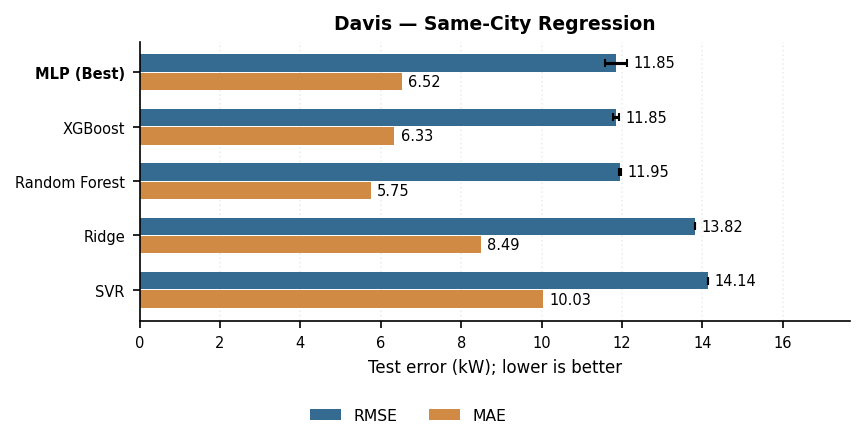

[SAVED] P2_Same_City_Amherst_Models.pdf


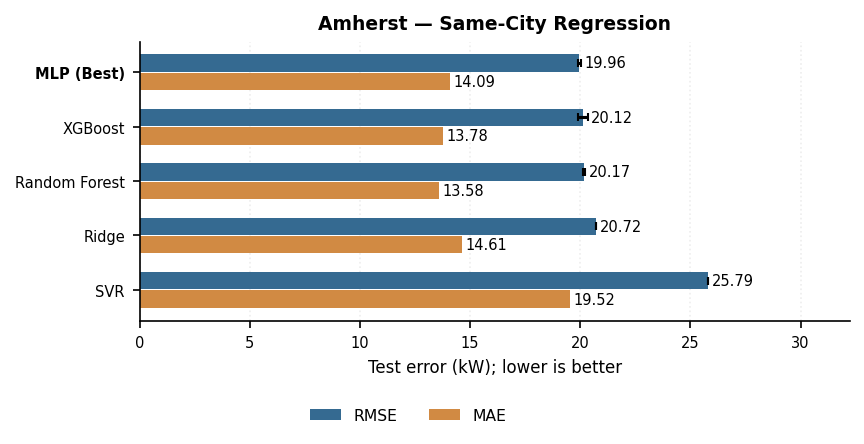

[SAVED] P2_Cross_City_All_Models.pdf


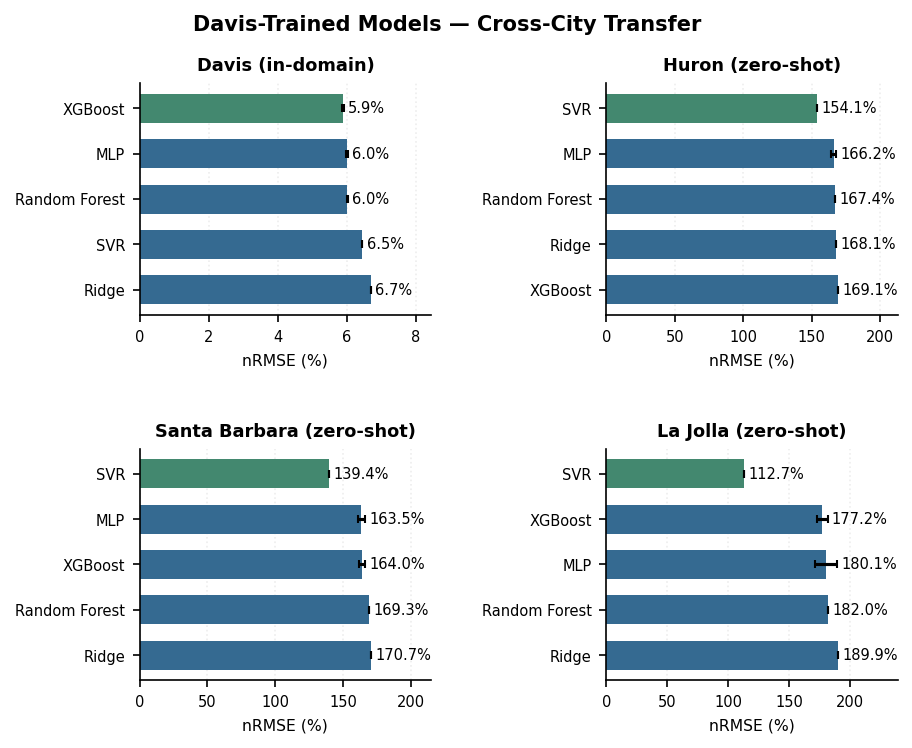

[SAVED] P2_Cross_City_Power_Bias.pdf


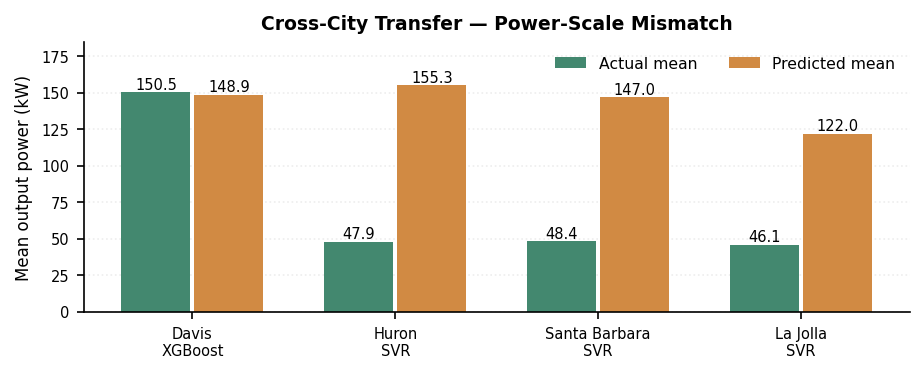

[SAVED] P2_Sequential_Davis_Models.pdf


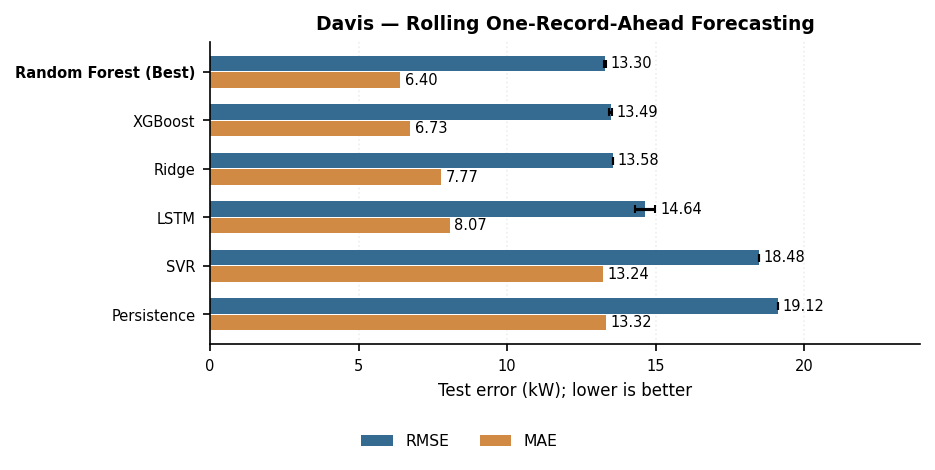

[SAVED] P2_Sequential_Amherst_Models.pdf


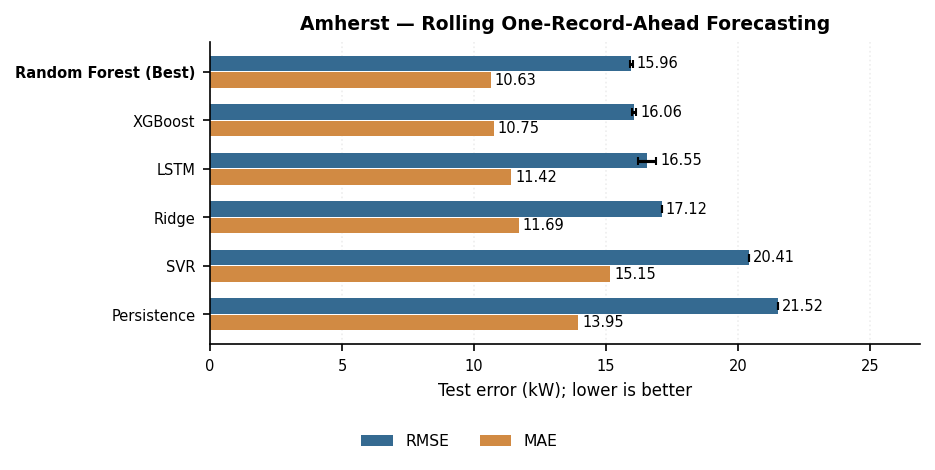

[SAVED] P2_Three_vs_Six_Years_Improvement.pdf


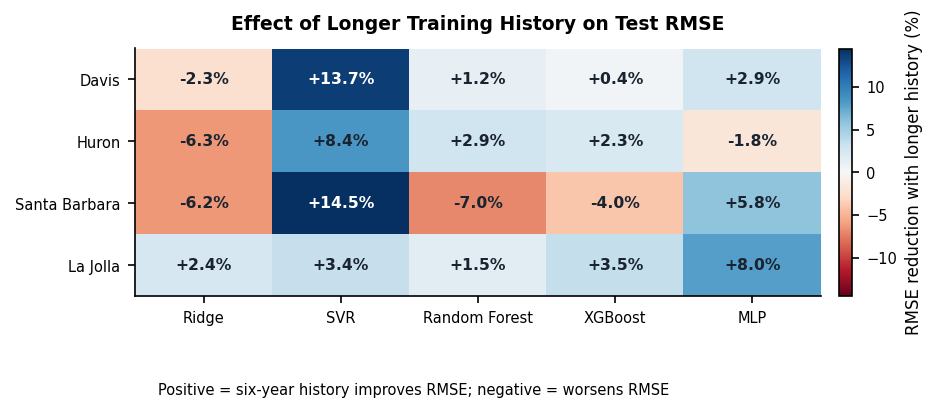

[SAVED] P2_Three_vs_Six_Years_Best_Models.pdf


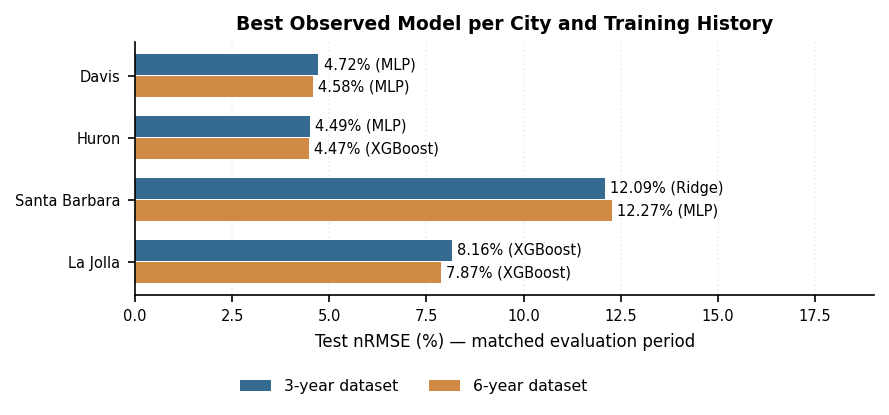

[SAVED] P2_Same_City_Davis_Prediction_Trace.pdf


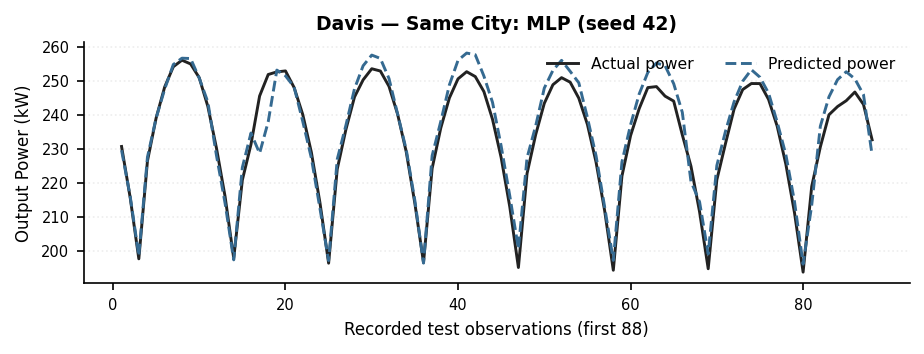

[SAVED] P2_Same_City_Amherst_Prediction_Trace.pdf


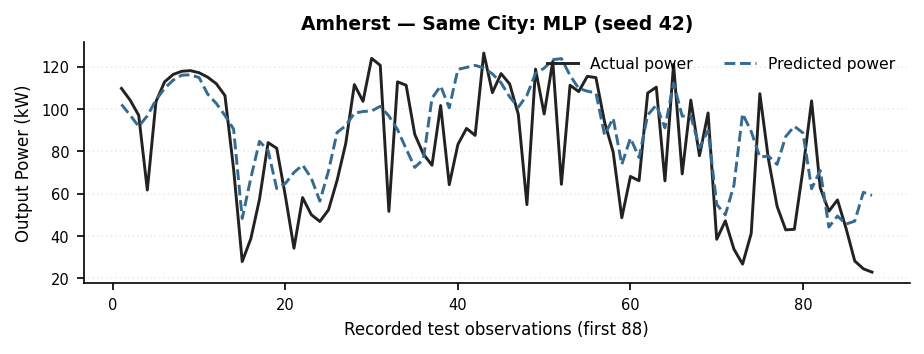

[SAVED] P2_Sequential_Davis_Prediction_Trace.pdf


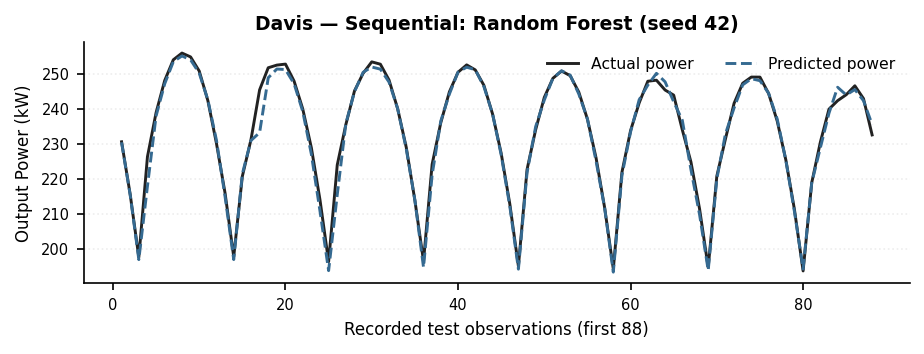

[SAVED] P2_Sequential_Amherst_Prediction_Trace.pdf


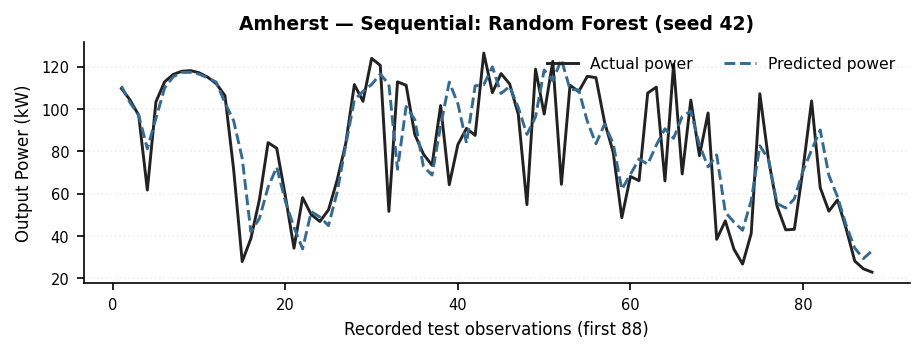


P2 — VISUALIZATION SUMMARY
Experiment records read : 240
Figures generated       : 12

Figure groups:
  Same-city        : 4 figures
  Cross-city       : 2 figures
  Sequential       : 4 figures
  Training history : 2 figures

PDF saving enabled: True
PDF folder: /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Figures/P2

No models were retrained.


In [17]:

# ============================================================
# P2 — Cell 13: Compact Results Visualizations for Overleaf
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SAVE_FINAL_FIGURES = True  # Preview first; True exports vector PDFs.
REPORT_WIDTH = 6.4
PLOT_SEED = 42                 # Fixed representative seed for traces.
TRACE_POINTS = 88             # First 88 recorded test observations.

BLUE, ORANGE, GREEN = "#356A91", "#D18A43", "#43886F"

MODEL_LABEL = {
    "Ridge Regression": "Ridge",
    "SVR (RBF)": "SVR",
    "Random Forest": "Random Forest",
    "XGBoost": "XGBoost",
    "MLP (PyTorch)": "MLP",
    "LSTM (PyTorch)": "LSTM",
    "Persistence": "Persistence"
}

CITIES_4 = ("Davis", "Huron", "Santa Barbara", "La Jolla")

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "figure.dpi": 150,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.facecolor": "white"
})

if SAVE_FINAL_FIGURES:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)

figure_count = 0


def show_report_figure(fig, name):
    """Display a figure; export a vector PDF only when enabled."""

    global figure_count
    figure_count += 1

    if SAVE_FINAL_FIGURES:
        fig.savefig(
            FIGURES_DIR / name,
            bbox_inches="tight",
            pad_inches=0.07
        )
        print(f"[SAVED] {name}")

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 1. Reload and summarize all saved regression experiments
# ------------------------------------------------------------

def results_summary(df, keys):
    """Calculate mean and standard deviation across seeds."""

    return df.groupby(keys, as_index=False).agg(
        RMSE=("RMSE (kW)", "mean"),
        RMSE_SD=("RMSE (kW)", "std"),
        MAE=("MAE (kW)", "mean"),
        MAE_SD=("MAE (kW)", "std"),
        nRMSE=("nRMSE (%)", "mean"),
        nRMSE_SD=("nRMSE (%)", "std"),
        Runs=("Seed", "count")
    )


same = pd.read_csv(
    RESULTS_DIR / "same_city_metrics.csv"
)

cross = pd.read_csv(
    RESULTS_DIR / "cross_city_metrics.csv"
)

sequence = pd.read_csv(
    RESULTS_DIR / "sequential_metrics.csv"
)

duration = pd.read_csv(
    RESULTS_DIR / "three_vs_six_year_metrics.csv"
)

assert (
    len(same),
    len(cross),
    len(sequence),
    len(duration)
) == (30, 60, 30, 120)

SAME = results_summary(
    same, ["City", "Model"]
)

CROSS = results_summary(
    cross, ["Evaluation City", "Model"]
)

SEQ = results_summary(
    sequence, ["City", "Model"]
)

DURATION = results_summary(
    duration, ["City", "History Years", "Model"]
)

assert (SAME.Runs == 3).all()
assert (CROSS.Runs == 3).all()
assert (SEQ.Runs == 3).all()
assert (DURATION.Runs == 3).all()


def test_leader(group):
    """Return the model with the lowest observed mean test RMSE."""

    return group.sort_values(
        ["RMSE", "Model"]
    ).iloc[0]


def load_saved_prediction(
    scenario, city, model, seed=PLOT_SEED
):
    """Read a prediction file without loading or fitting models."""

    slug = (
        model.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )

    city_slug = city.lower().replace(" ", "_")

    if scenario in ("Same_City", "Sequential"):
        filename = (
            f"{city_slug}_{slug}_seed{seed}.npz"
        )

    elif scenario == "Cross_City":
        filename = (
            f"davis_to_{city_slug}_{slug}_seed{seed}.npz"
        )

    else:
        raise ValueError(
            f"Unknown scenario: {scenario}"
        )

    path = (
        RESULTS_DIR / "Predictions"
        / scenario / filename
    )

    with np.load(path, allow_pickle=False) as data:
        return {
            key: data[key].copy()
            for key in ("row_index", "y_true", "y_pred")
        }


print("P2 — FINAL REPORT VISUALIZATIONS")
print("=" * 65)

print(f"Saved experiment records : {sum(map(len, (same, cross, sequence, duration)))}")
print(f"Figure saving enabled    : {SAVE_FINAL_FIGURES}")


# ------------------------------------------------------------
# 2. Same-city regression: all models (2 PDFs)
# ------------------------------------------------------------

for city in ("Davis", "Amherst"):

    group = (
        SAME[SAME.City == city]
        .sort_values("RMSE")
        .reset_index(drop=True)
    )

    leader = test_leader(group)["Model"]

    y = np.arange(len(group))

    fig, ax = plt.subplots(
        figsize=(REPORT_WIDTH, 3.1)
    )

    ax.barh(
        y - 0.17,
        group.RMSE,
        height=0.32,
        color=BLUE,
        xerr=group.RMSE_SD,
        capsize=2,
        label="RMSE"
    )

    ax.barh(
        y + 0.17,
        group.MAE,
        height=0.32,
        color=ORANGE,
        label="MAE"
    )

    for i, r in enumerate(group.itertuples()):

        ax.text(
            r.RMSE + r.RMSE_SD + 0.16,
            i - 0.17,
            f"{r.RMSE:.2f}",
            va="center",
            fontsize=7
        )

        ax.text(
            r.MAE + 0.16,
            i + 0.17,
            f"{r.MAE:.2f}",
            va="center",
            fontsize=7
        )

    ax.set_yticks(
        y,
        [
            MODEL_LABEL[m] + (
                " (Best)" if m == leader else ""
            )
            for m in group.Model
        ]
    )

    for tick, model in zip(
        ax.get_yticklabels(),
        group.Model
    ):
        if model == leader:
            tick.set_fontweight("bold")

    ax.invert_yaxis()

    ax.set_xlim(
        0,
        max(group.RMSE.max(), group.MAE.max()) * 1.25
    )

    ax.set_xlabel(
        "Test error (kW); lower is better"
    )

    ax.set_title(
        f"{city} — Same-City Regression",
        fontweight="bold"
    )

    ax.grid(
        axis="x",
        linestyle=":",
        alpha=0.22
    )
    ax.set_axisbelow(True)

    fig.legend(
        loc="lower center",
        ncol=2,
        frameon=False,
        bbox_to_anchor=(0.52, 0.01),
        fontsize=7.5
    )

    fig.subplots_adjust(
        left=0.24,
        right=0.98,
        top=0.86,
        bottom=0.26
    )

    show_report_figure(
        fig,
        f"P2_Same_City_{city}_Models.pdf"
    )


# ------------------------------------------------------------
# 3. Cross-city: all models, normalized RMSE (1 PDF)
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(REPORT_WIDTH, 5.1)
)

for ax, city in zip(axes.flat, CITIES_4):

    group = (
        CROSS[CROSS["Evaluation City"] == city]
        .sort_values("nRMSE")
    )

    winner = test_leader(group)["Model"]

    y = np.arange(len(group))

    values = group.nRMSE.to_numpy()
    deviations = group.nRMSE_SD.to_numpy()

    colors = [
        GREEN if m == winner else BLUE
        for m in group.Model
    ]

    ax.barh(
        y,
        values,
        xerr=deviations,
        color=colors,
        height=0.64,
        capsize=2
    )

    ax.set_yticks(
        y,
        [MODEL_LABEL[m] for m in group.Model]
    )

    ax.invert_yaxis()

    ax.set_xlim(
        0,
        (values + deviations).max() * 1.26
    )

    city_type = (
        "in-domain" if city == "Davis"
        else "zero-shot"
    )

    ax.set_title(
        f"{city} ({city_type})",
        fontweight="bold",
        fontsize=8.5
    )

    for i, (value, sd) in enumerate(
        zip(values, deviations)
    ):

        ax.text(
            value + sd + ax.get_xlim()[1] * 0.015,
            i,
            f"{value:.1f}%",
            va="center",
            fontsize=7
        )

    ax.grid(
        axis="x",
        linestyle=":",
        alpha=0.22
    )
    ax.set_axisbelow(True)

    ax.set_xlabel(
        "nRMSE (%)",
        fontsize=7.5
    )

fig.suptitle(
    "Davis-Trained Models — Cross-City Transfer",
    fontsize=10,
    fontweight="bold"
)

fig.subplots_adjust(
    left=0.18,
    right=0.97,
    top=0.89,
    bottom=0.11,
    wspace=0.60,
    hspace=0.58
)

show_report_figure(
    fig,
    "P2_Cross_City_All_Models.pdf"
)


# ------------------------------------------------------------
# 4. Cross-city power-scale mismatch (1 PDF)
# ------------------------------------------------------------

actual_means = []
predicted_means = []
tick_labels = []

for city in CITIES_4:

    winner = test_leader(
        CROSS[CROSS["Evaluation City"] == city]
    )["Model"]

    predicted_seeds = []

    for seed in SEEDS:

        data = load_saved_prediction(
            "Cross_City",
            city,
            winner,
            seed
        )

        predicted_seeds.append(
            float(np.mean(data["y_pred"]))
        )

    actual_means.append(
        float(np.mean(data["y_true"]))
    )

    predicted_means.append(
        float(np.mean(predicted_seeds))
    )

    tick_labels.append(
        city + "\n" + MODEL_LABEL[winner]
    )

fig, ax = plt.subplots(
    figsize=(REPORT_WIDTH, 3.05)
)

x = np.arange(len(CITIES_4))

ax.bar(
    x - 0.18,
    actual_means,
    0.34,
    label="Actual mean",
    color=GREEN
)

ax.bar(
    x + 0.18,
    predicted_means,
    0.34,
    label="Predicted mean",
    color=ORANGE
)

for k, value in enumerate(actual_means):

    ax.text(
        k - 0.18,
        value + 2,
        f"{value:.1f}",
        ha="center",
        fontsize=7
    )

for k, value in enumerate(predicted_means):

    ax.text(
        k + 0.18,
        value + 2,
        f"{value:.1f}",
        ha="center",
        fontsize=7
    )

ax.set_xticks(x, tick_labels)
ax.set_ylabel("Mean output power (kW)")

ax.set_ylim(
    0,
    max(predicted_means + actual_means) * 1.19
)

ax.set_title(
    "Cross-City Transfer — Power-Scale Mismatch",
    fontweight="bold"
)

ax.grid(
    axis="y",
    linestyle=":",
    alpha=0.22
)
ax.set_axisbelow(True)

ax.legend(
    ncol=2,
    frameon=False,
    loc="upper right",
    fontsize=7.5
)

fig.subplots_adjust(
    left=0.12,
    right=0.98,
    top=0.86,
    bottom=0.27
)

show_report_figure(
    fig,
    "P2_Cross_City_Power_Bias.pdf"
)


# ------------------------------------------------------------
# 5. Sequential forecasting: all models and persistence
# ------------------------------------------------------------

for city, dataset_name in (
    ("Davis", "Davis_3yr"),
    ("Amherst", "Amherst_3yr")
):

    baseline = get_forecast_partition(
        dataset_name,
        "test"
    )

    scores = evaluate_regression(
        baseline["y"],
        baseline["last_observed_power"]
    )

    group = SEQ[SEQ.City == city].copy()

    leader = test_leader(group)["Model"]

    persistence = pd.DataFrame([{
        "City": city,
        "Model": "Persistence",
        "RMSE": scores["RMSE (kW)"],
        "RMSE_SD": 0.0,
        "MAE": scores["MAE (kW)"],
        "MAE_SD": 0.0
    }])

    group = (
        pd.concat(
            [group, persistence],
            ignore_index=True
        )
        .sort_values("RMSE")
    )

    y = np.arange(len(group))

    fig, ax = plt.subplots(
        figsize=(REPORT_WIDTH, 3.3)
    )

    ax.barh(
        y - 0.17,
        group.RMSE,
        height=0.32,
        color=BLUE,
        xerr=group.RMSE_SD,
        capsize=2,
        label="RMSE"
    )

    ax.barh(
        y + 0.17,
        group.MAE,
        height=0.32,
        color=ORANGE,
        label="MAE"
    )

    for i, r in enumerate(group.itertuples()):

        ax.text(
            r.RMSE + r.RMSE_SD + 0.15,
            i - 0.17,
            f"{r.RMSE:.2f}",
            va="center",
            fontsize=7
        )

        ax.text(
            r.MAE + 0.15,
            i + 0.17,
            f"{r.MAE:.2f}",
            va="center",
            fontsize=7
        )

    ax.set_yticks(
        y,
        [
            MODEL_LABEL[m] + (
                " (Best)" if m == leader else ""
            )
            for m in group.Model
        ]
    )

    for tick, model in zip(
        ax.get_yticklabels(),
        group.Model
    ):
        if model == leader:
            tick.set_fontweight("bold")

    ax.invert_yaxis()

    ax.set_xlim(
        0,
        max(group.RMSE.max(), group.MAE.max()) * 1.25
    )

    ax.set_title(
        f"{city} — Rolling One-Record-Ahead Forecasting",
        fontweight="bold"
    )

    ax.set_xlabel(
        "Test error (kW); lower is better"
    )

    ax.grid(
        axis="x",
        linestyle=":",
        alpha=0.22
    )
    ax.set_axisbelow(True)

    fig.legend(
        ncol=2,
        frameon=False,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.01),
        fontsize=7.5
    )

    fig.subplots_adjust(
        left=0.24,
        right=0.98,
        top=0.86,
        bottom=0.25
    )

    show_report_figure(
        fig,
        f"P2_Sequential_{city}_Models.pdf"
    )


# ------------------------------------------------------------
# 6. Three-year vs. six-year: all-model improvement heatmap
# ------------------------------------------------------------

model_order = (
    *CLASSICAL_MODELS,
    "MLP (PyTorch)"
)

improvement = np.zeros(
    (len(CITIES_4), len(model_order))
)

for i, city in enumerate(CITIES_4):

    for j, model in enumerate(model_order):

        subset = DURATION[
            (DURATION.City == city)
            & (DURATION.Model == model)
        ]

        rmse_3 = float(
            subset.loc[
                subset["History Years"] == 3,
                "RMSE"
            ].iloc[0]
        )

        rmse_6 = float(
            subset.loc[
                subset["History Years"] == 6,
                "RMSE"
            ].iloc[0]
        )

        improvement[i, j] = (
            100 * (rmse_3 - rmse_6) / rmse_3
        )

fig, ax = plt.subplots(
    figsize=(REPORT_WIDTH, 2.8)
)

limit = max(
    8,
    float(np.max(np.abs(improvement)))
)

image = ax.imshow(
    improvement,
    cmap="RdBu",
    vmin=-limit,
    vmax=limit,
    aspect="auto"
)

ax.set_yticks(
    np.arange(len(CITIES_4)),
    CITIES_4
)

ax.set_xticks(
    np.arange(len(model_order)),
    [MODEL_LABEL[m] for m in model_order]
)

for i in range(len(CITIES_4)):
    for j in range(len(model_order)):

        value = improvement[i, j]

        ax.text(
            j,
            i,
            f"{value:+.1f}%",
            ha="center",
            va="center",
            color=(
                "white"
                if abs(value) > limit * 0.58
                else "#1A2430"
            ),
            fontsize=7.5,
            fontweight="bold"
        )

ax.set_title(
    "Effect of Longer Training History on Test RMSE",
    fontweight="bold",
    pad=9
)

fig.colorbar(
    image,
    ax=ax,
    fraction=0.035,
    pad=0.025,
    label="RMSE reduction with longer history (%)"
)

fig.text(
    0.48,
    0.025,
    "Positive = six-year history improves RMSE; "
    "negative = worsens RMSE",
    ha="center",
    fontsize=7
)

fig.subplots_adjust(
    left=0.19,
    right=0.95,
    top=0.85,
    bottom=0.26
)

show_report_figure(
    fig,
    "P2_Three_vs_Six_Years_Improvement.pdf"
)


# ------------------------------------------------------------
# 7. Three-year vs. six-year: best model per city (1 PDF)
# ------------------------------------------------------------

best_3 = []
best_6 = []

for city in CITIES_4:

    for years, target in (
        (3, best_3),
        (6, best_6)
    ):

        subset = DURATION[
            (DURATION.City == city)
            & (DURATION["History Years"] == years)
        ]

        target.append(
            test_leader(subset)
        )

fig, ax = plt.subplots(
    figsize=(REPORT_WIDTH, 2.9)
)

y = np.arange(len(CITIES_4))

ax.barh(
    y - 0.18,
    [r.nRMSE for r in best_3],
    0.34,
    label="3-year dataset",
    color=BLUE
)

ax.barh(
    y + 0.18,
    [r.nRMSE for r in best_6],
    0.34,
    label="6-year dataset",
    color=ORANGE
)

ax.set_yticks(y, CITIES_4)
ax.invert_yaxis()

max_value = max(
    [r.nRMSE for r in best_3 + best_6]
)

ax.set_xlim(
    0,
    max_value * 1.55
)

for i in range(len(CITIES_4)):

    for item, offset in (
        (best_3[i], -0.18),
        (best_6[i], 0.18)
    ):

        ax.text(
            item.nRMSE + 0.14,
            i + offset,
            f"{item.nRMSE:.2f}% "
            f"({MODEL_LABEL[item.Model]})",
            va="center",
            fontsize=7
        )

ax.set_title(
    "Best Observed Model per City and Training History",
    fontweight="bold"
)

ax.set_xlabel(
    "Test nRMSE (%) — matched evaluation period"
)

ax.grid(
    axis="x",
    linestyle=":",
    alpha=0.22
)
ax.set_axisbelow(True)

fig.legend(
    loc="lower center",
    bbox_to_anchor=(0.50, 0.01),
    ncol=2,
    frameon=False,
    fontsize=7.5
)

fig.subplots_adjust(
    left=0.21,
    right=0.98,
    top=0.85,
    bottom=0.27
)

show_report_figure(
    fig,
    "P2_Three_vs_Six_Years_Best_Models.pdf"
)


# ------------------------------------------------------------
# 8. Prediction-versus-actual traces (4 PDFs)
# ------------------------------------------------------------

# A fixed seed is used for representative visualizations.
# All model rankings remain based on three-seed mean RMSE.

for scenario, summary_table, cities in (
    ("Same_City", SAME, ("Davis", "Amherst")),
    ("Sequential", SEQ, ("Davis", "Amherst"))
):

    for city in cities:

        winner = test_leader(
            summary_table[
                summary_table.City == city
            ]
        )["Model"]

        prediction = load_saved_prediction(
            scenario,
            city,
            winner
        )

        number = min(
            TRACE_POINTS,
            len(prediction["y_true"])
        )

        x = np.arange(1, number + 1)

        fig, ax = plt.subplots(
            figsize=(REPORT_WIDTH, 2.55)
        )

        ax.plot(
            x,
            prediction["y_true"][:number],
            label="Actual power",
            color="#222222",
            linewidth=1.4
        )

        ax.plot(
            x,
            prediction["y_pred"][:number],
            label="Predicted power",
            color=BLUE,
            linewidth=1.4,
            linestyle="--"
        )

        scenario_title = scenario.replace("_", " ")

        ax.set_title(
            f"{city} — {scenario_title}: "
            f"{MODEL_LABEL[winner]} (seed {PLOT_SEED})",
            fontweight="bold"
        )

        ax.set_xlabel(
            f"Recorded test observations (first {number})"
        )

        ax.set_ylabel(
            "Output Power (kW)"
        )

        ax.grid(
            axis="y",
            linestyle=":",
            alpha=0.22
        )

        ax.legend(
            ncol=2,
            frameon=False,
            loc="upper right",
            fontsize=7.5
        )

        fig.subplots_adjust(
            left=0.12,
            right=0.98,
            top=0.86,
            bottom=0.23
        )

        show_report_figure(
            fig,
            f"P2_{scenario}_{city}_Prediction_Trace.pdf"
        )


# ------------------------------------------------------------
# 9. Completion summary
# ------------------------------------------------------------

print("\nP2 — VISUALIZATION SUMMARY")
print("=" * 65)

print(
    "Experiment records read : "
    f"{len(same) + len(cross) + len(sequence) + len(duration)}"
)

print(f"Figures generated       : {figure_count}")

print("\nFigure groups:")
print("  Same-city        : 4 figures")
print("  Cross-city       : 2 figures")
print("  Sequential       : 4 figures")
print("  Training history : 2 figures")

print(f"\nPDF saving enabled: {SAVE_FINAL_FIGURES}")

if SAVE_FINAL_FIGURES:
    print(f"PDF folder: {FIGURES_DIR}")
else:
    print(
        "PREVIEW ONLY — Change SAVE_FINAL_FIGURES "
        "to True to export PDFs."
    )

print("\nNo models were retrained.")
